# Projet Algorithme d'apprentissage : Prédiction des Résultats de Ligue 1 (2025-2026)



Mael Paget & Victor Michelon  


---

## Objectif du Projet

L'objectif de ce notebook est de concevoir un pipeline complet de Machine Learning capable de prédire l'issue de l'ensemble des matchs de la saison de Ligue 1 2025-2026.

La prédiction s'articule autour d'une classification multiclasse :
* **1** : Victoire de l'équipe à domicile
* **0** : Match nul
* **-1** : Victoire de l'équipe à l'extérieur

Pour y parvenir, nous ne nous contentons pas de l'historique brut des rencontres. Ce projet s'appuie sur une modélisation du contexte d'avant-match en combinant plusieurs dimensions :
- la puissance financière des effectifs
- le *momentum* récent
- la dynamique de classement
- l'historique des confrontations directes et les statistiques d'événements de jeu (cartons, passes décisives).

L'enjeu majeur pour un projet avec des séries temporelles comme ici est la création d'un pipeline de données sans data leakage.

---

## Sommaire

1. **Setup — Imports & Chargement des Données** *Préparation de l'environnement et fusion des datasets initiaux.*
2. **Analyse Exploratoire des Données (EDA)** *Étude de l'avantage à domicile, de l'impact financier, de l'importance du classement et des corrélations.*
3. **Feature Engineering & Prévention du Data Leakage** *Création des variables contextuelles (Target Encoding, Forme H/A, Écarts financiers) avec des fenêtres glissantes strictes.*
4. **Développement du modèle de prédiction** *Entraînement des modèles (Random Forest, Gradient Boosting, Regression Logistique) avec pondération temporelle.*
5. **Prédictions Saison 2025-2026** *Génération du contexte actuel et inférence sur le calendrier à venir.*
6. **Export des Résultats** *Formatage de la soumission finale.*



---
## **1. Setup — Imports & Chargement**

In [109]:
# @title
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier

pd.set_option('display.max_columns', None)

In [110]:
matches    = pd.read_csv('matchs_2013_2024.csv')
matches_2025 = pd.read_csv('match_2025.csv')
player_val = pd.read_csv('player_valuation_before_season.csv')
game_events = pd.read_csv('game_events_before2025.csv')
sample_results = pd.read_csv('sample_results.csv')

for df in [matches, matches_2025, player_val, game_events]:
    df['date'] = pd.to_datetime(df['date'])

matches = (
    matches[matches['competition_type'] == 'domestic_league']
    .sort_values('date')
    .reset_index(drop=True)
)
matches['match_year']  = matches['date'].dt.year
matches['total_goals'] = matches['home_club_goals'] + matches['away_club_goals']

SEASON_MAX = matches['season'].max()

print(f'Matchs historiques : {len(matches):,}  ({matches["season"].min()}–{SEASON_MAX})')
print(f'Matchs à prédire   : {len(matches_2025):,}')
print(f'Événements de jeu  : {len(game_events):,}')
print(f'Valorisations      : {len(player_val):,}')

Matchs historiques : 4,691  (2012–2024)
Matchs à prédire   : 233
Événements de jeu  : 61,944
Valorisations      : 32,856


# **2 - Analyse Exploratoire des données d'entrainement: matchs de Ligue 1 (2012–2024)**

> Cette EDA a pour objectif de comprendre les forces sous-jacentes qui déterminent les résultats des matchs de Ligue 1, et de valider la pertinence des features de notre pipeline de prédiction.

5 axes d'analyse :
1. Jouer à Domicile confère t'il vraiment un avantage pour l'issue du match?
2. La valeur financière des effectifs comme prédicteur de résultat
3. La dynamique de classement et l'effet des écarts de niveau
4. Etude de la forme récente : le "Momentum"
5. Les confrontations directes (H2H) & la concentration du niveau

## 2.1 - Données de support pour l'EDA

In [111]:
# @title
DARK_BG   = '#0f1117'
PANEL_BG  = '#1a1d27'
GRID_CLR  = '#2a2d3a'
TEXT_CLR  = '#e8e8f0'
MUTED_CLR = '#7a7d94'
C_WIN     = '#4ade80'
C_DRAW    = '#facc15'
C_LOSS    = '#f87171'
C_ACC     = '#818cf8'
C_GOLD    = '#fbbf24'
C_BLUE    = '#38bdf8'

plt.rcParams.update({
    'figure.facecolor': DARK_BG,  'axes.facecolor':  PANEL_BG,
    'axes.edgecolor':   GRID_CLR, 'axes.labelcolor': TEXT_CLR,
    'axes.titlecolor':  TEXT_CLR, 'axes.grid':        True,
    'grid.color':       GRID_CLR, 'grid.linewidth':   0.6,
    'xtick.color':      MUTED_CLR,'ytick.color':      MUTED_CLR,
    'text.color':       TEXT_CLR, 'font.family':      'monospace',
    'legend.facecolor': PANEL_BG, 'legend.edgecolor': GRID_CLR,
    'legend.labelcolor':TEXT_CLR,
})

def title_box(ax, title, subtitle=None):
    ax.set_title(title, fontsize=13, fontweight='bold', color=TEXT_CLR, pad=14)
    if subtitle:
        ax.text(0.5, 1.015, subtitle, transform=ax.transAxes,
                fontsize=8, color=MUTED_CLR, ha='center', va='bottom', style='italic')

fr1_val_eda = player_val[player_val['player_club_domestic_competition_id'] == 'FR1'].copy()
fr1_val_eda['year'] = fr1_val_eda['date'].dt.year
squad_val_eda = (
    fr1_val_eda.groupby(['current_club_id','year'])['market_value_in_eur']
    .sum().reset_index()
    .rename(columns={'current_club_id':'club_id','market_value_in_eur':'squad_value'})
)

m_eda = matches.merge(
    squad_val_eda.rename(columns={'club_id':'home_club_id','year':'match_year','squad_value':'h_val'}),
    on=['home_club_id','match_year'], how='left'
).merge(
    squad_val_eda.rename(columns={'club_id':'away_club_id','year':'match_year','squad_value':'a_val'}),
    on=['away_club_id','match_year'], how='left'
)
m_eda['val_ratio']    = m_eda['h_val'] / m_eda['a_val'].replace(0, np.nan)
m_eda['log_val_diff'] = np.log1p(m_eda['h_val']) - np.log1p(m_eda['a_val'])

def rolling_form_eda(df, w=5):
    home_v = df[['game_id','date','home_club_id','results']].rename(
        columns={'home_club_id':'club_id'}).copy()
    home_v['pts'] = home_v['results'].map({1:3, 0:1, -1:0})
    home_v = home_v.sort_values(['club_id','date'])
    home_v['form_pts'] = home_v.groupby('club_id')['pts'].transform(
        lambda x: x.shift(1).rolling(w, min_periods=w).sum())

    away_v = df[['game_id','date','away_club_id','results']].rename(
        columns={'away_club_id':'club_id'}).copy()
    away_v['pts'] = away_v['results'].map({1:0, 0:1, -1:3})
    away_v = away_v.sort_values(['club_id','date'])
    away_v['form_pts'] = away_v.groupby('club_id')['pts'].transform(
        lambda x: x.shift(1).rolling(w, min_periods=w).sum())

    df = df.merge(home_v[['game_id','club_id','form_pts']]
                  .rename(columns={'club_id':'home_club_id','form_pts':'h_form'}),
                  on=['game_id','home_club_id'], how='left')
    df = df.merge(away_v[['game_id','club_id','form_pts']]
                  .rename(columns={'club_id':'away_club_id','form_pts':'a_form'}),
                  on=['game_id','away_club_id'], how='left')
    df['diff_form'] = df['h_form'] - df['a_form']
    return df

m_form_eda = rolling_form_eda(matches)
print('Données EDA prêtes')

Données EDA prêtes


## 2.2 - L'avantage du terrain en Ligue 1

> L'objectif ici est d'analyser si l'équipe à domicile gagne significativement plus souvent, et si cet avantage est stable dans le temps. On cherche à savoir si le fait de jouer à domicile est une donnée de match qu'on peut exploiter pour prévoir l'issue du match, et dans quelle mesure.

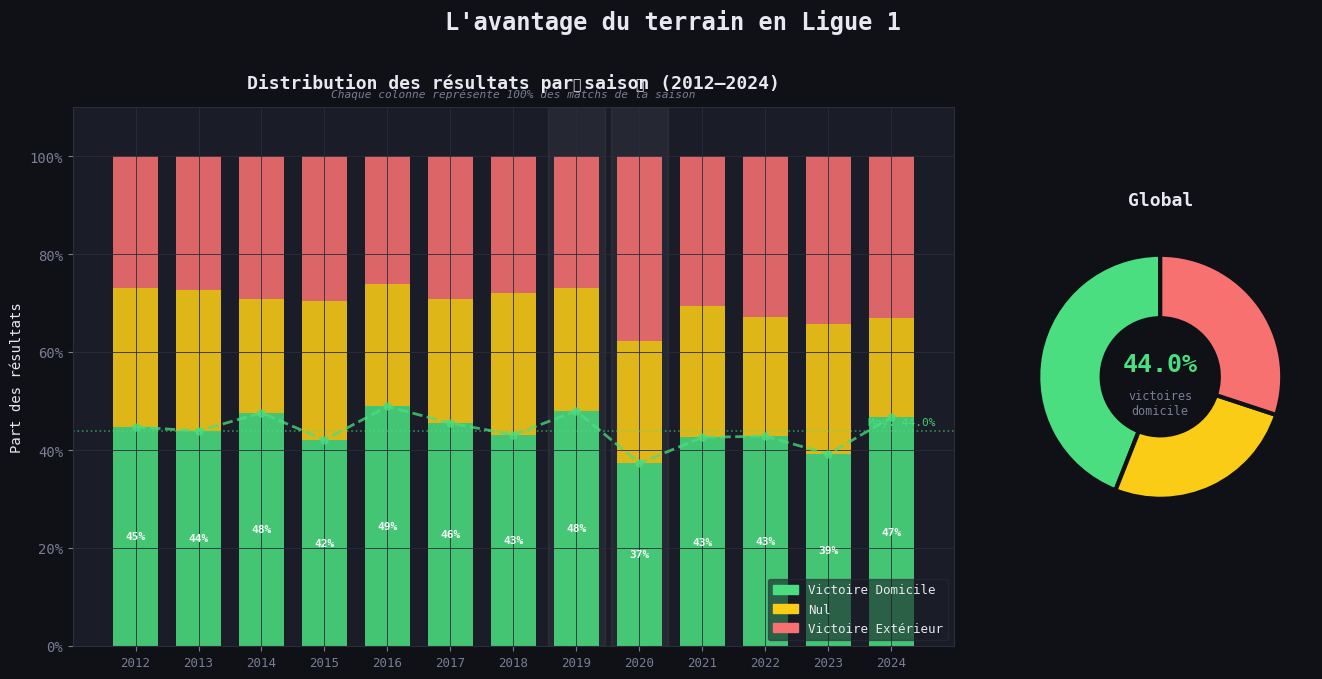

In [112]:
# @title
by_season = (matches.groupby('season')['results']
             .value_counts(normalize=True).unstack().fillna(0)
             .rename(columns={1:'Domicile', 0:'Nul', -1:'Extérieur'}))
seasons = by_season.index.tolist()
overall = matches['results'].value_counts(normalize=True)
avg_dom = overall.get(1, 0)

fig = plt.figure(figsize=(16, 7), facecolor=DARK_BG)
gs  = gridspec.GridSpec(1, 3, figure=fig, width_ratios=[2.6, 0.04, 0.9], wspace=0.05)
ax_main = fig.add_subplot(gs[0])
ax_ring = fig.add_subplot(gs[2])

x = np.arange(len(seasons))
ax_main.bar(x, by_season['Domicile'], 0.72, color=C_WIN,  alpha=0.88)
ax_main.bar(x, by_season['Nul'],      0.72, color=C_DRAW, alpha=0.88,
            bottom=by_season['Domicile'])
ax_main.bar(x, by_season['Extérieur'],0.72, color=C_LOSS, alpha=0.88,
            bottom=by_season['Domicile'] + by_season['Nul'])
ax_main.plot(x, by_season['Domicile'], color=C_WIN, lw=2, marker='o', ms=5,
             zorder=10, ls='--', alpha=0.75)

for s in [2019, 2020]:
    if s in seasons:
        xi = seasons.index(s)
        ax_main.axvspan(xi-0.45, xi+0.45, color='white', alpha=0.05, zorder=0)
        ax_main.text(xi, 1.035, '🦠', ha='center', fontsize=10,
                     transform=ax_main.get_xaxis_transform())

ax_main.axhline(avg_dom, color=C_WIN, lw=1.2, ls=':', alpha=0.55)
ax_main.text(len(seasons)-0.3, avg_dom+0.01, f'Moy. {avg_dom:.1%}',
             color=C_WIN, fontsize=8, alpha=0.9, ha='right')

for xi, s in enumerate(seasons):
    v = by_season.loc[s, 'Domicile']
    ax_main.text(xi, v/2, f'{v:.0%}', ha='center', va='center',
                 fontsize=8, color='white', fontweight='bold', alpha=0.95)

ax_main.set_xticks(x)
ax_main.set_xticklabels(seasons, fontsize=9)
ax_main.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0%}'))
ax_main.set_ylim(0, 1.1)
ax_main.set_ylabel('Part des résultats', fontsize=10)
ax_main.legend([mpatches.Patch(color=c) for c in [C_WIN, C_DRAW, C_LOSS]],
               ['Victoire Domicile','Nul','Victoire Extérieur'],
               loc='lower right', fontsize=9, framealpha=0.6)
title_box(ax_main, "Distribution des résultats par saison (2012–2024)",
          "Chaque colonne représente 100% des matchs de la saison")

sizes = [overall.get(1,0), overall.get(0,0), overall.get(-1,0)]
ax_ring.pie(sizes, colors=[C_WIN, C_DRAW, C_LOSS],
            wedgeprops={'width':0.52, 'edgecolor':DARK_BG, 'linewidth':3}, startangle=90)
ax_ring.text(0,  0.10, f'{sizes[0]:.1%}', ha='center', va='center',
             fontsize=18, fontweight='bold', color=C_WIN)
ax_ring.text(0, -0.22, 'victoires\ndomicile', ha='center', va='center',
             fontsize=8.5, color=MUTED_CLR)
ax_ring.set_facecolor(DARK_BG)
title_box(ax_ring, "Global")

fig.suptitle("L'avantage du terrain en Ligue 1",
             fontsize=17, fontweight='bold', color=TEXT_CLR, y=1.02)
plt.tight_layout()
plt.show()

### Analyse & interprétation de l'avantage du terrain

L'avantage du terrain est un prédicteur avéré. On observe que l'équipe à domicile s'impose dans 44% des cas, contre 30% à l'extérieur et 26% de nuls. Cet écart significatif de 14 points confirme l’impact du public, comme le montre d’ailleurs la chute des victoires à domicile lors de la saison Covid jouée à huis clos

Face à ce déséquilibre des classes, le risque est d'obtenir un modèle paresseux qui prédirait systématiquement la victoire à domicile. Nous utiliserons donc le paramètre class_weight='balanced' pour forcer l'algorithme à chercher des motifs plus complexes en pénalisant plus les erreurs sur les matchs nuls et les victoires à l'extérieur.

Enfin, on note une légère progression globale des victoires à l'extérieur ces dernières années. Pour capter cette dynamique récente, nous appliquerons une pondération temporelle (sample_weights) lors de l'entraînement, accordant mécaniquement plus d'importance aux saisons les plus proches.

## 2.3 — Valeur financière des effectifs et résultats

> Le rapport de valeur entre deux effectifs prédit-il le résultat ? Y a-t-il un seuil à partir duquel la domination financière devient déterminante ?

Création des indicateurs financiers :
On agrège d'abord la valeur marchande individuelle (estimée avant le début de saison) de tous les joueurs d'un club pour obtenir la valeur totale de son effectif sur l'année. À partir de là, on calcule le ratio financier (valeur domicile divisée par valeur extérieur) ainsi que l'écart logarithmique entre les deux équipes, ce qui permet d'atténuer mathématiquement le poids des valeurs extrêmes.

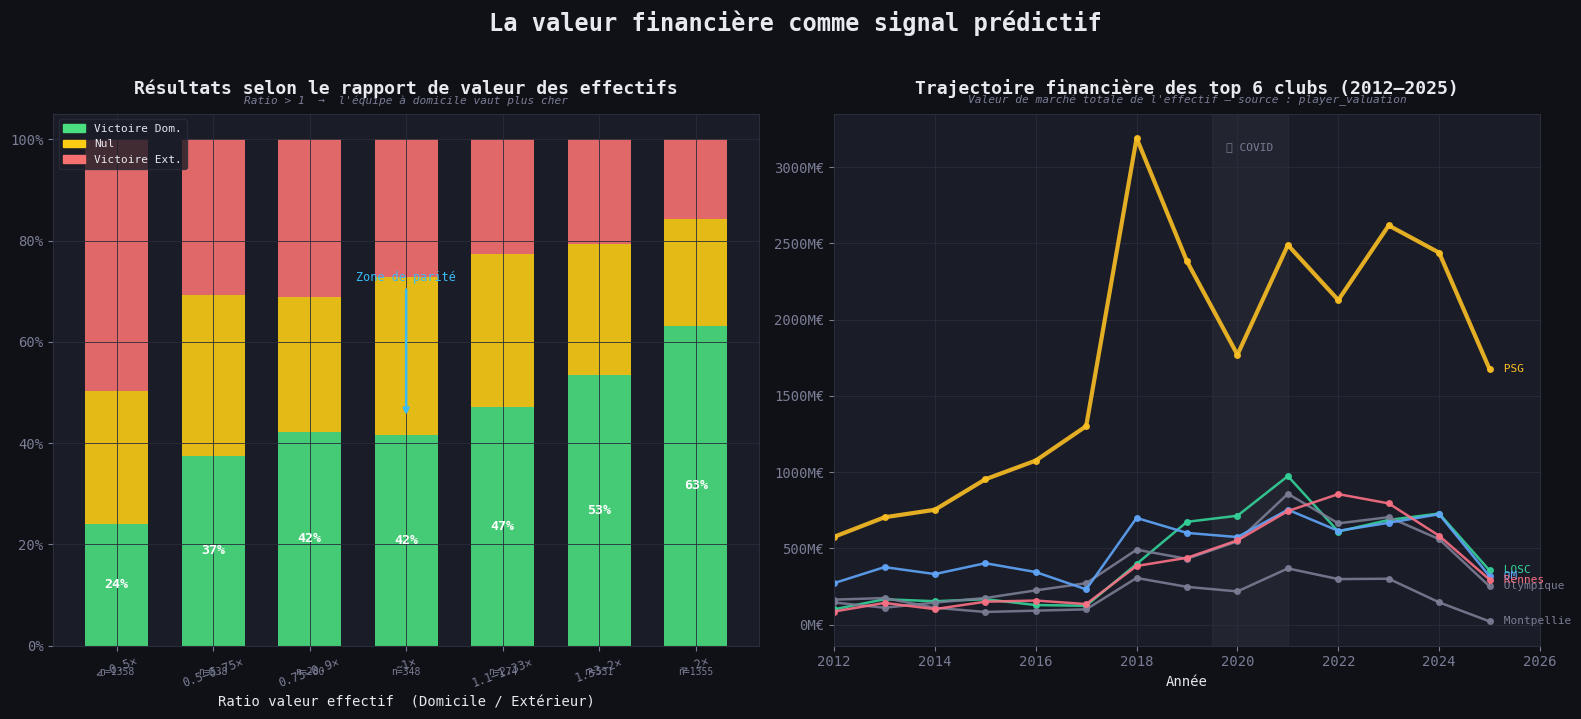

In [113]:
# @title
ratio_bins   = [0, 0.5, 0.75, 0.9, 1.11, 1.33, 2.0, 100]
ratio_labels = ['< 0.5×', '0.5–0.75×', '0.75–0.9×', '~1×', '1.1–1.33×', '1.33–2×', '> 2×']
m_clean = m_eda.dropna(subset=['val_ratio']).copy()
m_clean['ratio_bucket'] = pd.cut(m_clean['val_ratio'], bins=ratio_bins, labels=ratio_labels)
bucket_stats = (m_clean.groupby('ratio_bucket', observed=True)['results']
                .value_counts(normalize=True).unstack().fillna(0)
                .rename(columns={1:'Dom.', 0:'Nul', -1:'Ext.'}))
bucket_n = m_clean.groupby('ratio_bucket', observed=True).size()

club_names_eda = (matches[['home_club_id','home_club_name']].drop_duplicates()
                  .rename(columns={'home_club_id':'club_id','home_club_name':'name'}))
sv_named = squad_val_eda.merge(club_names_eda, on='club_id', how='left')
top_ids  = matches.groupby('home_club_id')['game_id'].count().nlargest(6).index
sv_top   = sv_named[sv_named['club_id'].isin(top_ids) & (sv_named['year'] >= 2012)]

fig, axes = plt.subplots(1, 2, figsize=(16, 7), facecolor=DARK_BG)

ax = axes[0]
x  = np.arange(len(ratio_labels))
ax.bar(x, bucket_stats['Dom.'], 0.65, color=C_WIN,  alpha=0.9)
ax.bar(x, bucket_stats['Nul'],  0.65, color=C_DRAW, alpha=0.9, bottom=bucket_stats['Dom.'])
ax.bar(x, bucket_stats['Ext.'], 0.65, color=C_LOSS, alpha=0.9,
       bottom=bucket_stats['Dom.'] + bucket_stats['Nul'])

for xi, lbl in enumerate(ratio_labels):
    if lbl not in bucket_stats.index: continue
    v = bucket_stats.loc[lbl, 'Dom.']
    n = bucket_n.get(lbl, 0)
    ax.text(xi, v/2, f'{v:.0%}', ha='center', va='center', fontsize=9.5,
            fontweight='bold', color='white')
    ax.text(xi, -0.055, f'n={n}', ha='center', fontsize=7,
            color=MUTED_CLR, transform=ax.get_xaxis_transform())

ax.annotate('Zone de parité', xy=(3, 0.45), xytext=(3, 0.72),
            arrowprops=dict(arrowstyle='->', color=C_BLUE, lw=1.8),
            color=C_BLUE, fontsize=8.5, ha='center')
ax.set_xticks(x)
ax.set_xticklabels(ratio_labels, fontsize=8.5, rotation=20)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_ylim(0, 1.05)
ax.set_xlabel('Ratio valeur effectif  (Domicile / Extérieur)', fontsize=10)
ax.legend([mpatches.Patch(color=c) for c in [C_WIN, C_DRAW, C_LOSS]],
          ['Victoire Dom.','Nul','Victoire Ext.'], loc='upper left', fontsize=8)
title_box(ax, "Résultats selon le rapport de valeur des effectifs",
          "Ratio > 1  →  l'équipe à domicile vaut plus cher")

ax2 = axes[1]
club_palette = {
    'Paris Saint-Germain Football Club':            C_GOLD,
    'Olympique de Marseille':                       '#60a5fa',
    'Olympique Lyonnais':                           '#f97316',
    'Association sportive de Monaco Football Club': '#e879f9',
    'Lille Olympique Sporting Club':                '#34d399',
    'Stade Rennais Football Club':                  '#fb7185',
}
short_names = {
    'Paris Saint-Germain Football Club':            'PSG',
    'Olympique de Marseille':                       'OM',
    'Olympique Lyonnais':                           'OL',
    'Association sportive de Monaco Football Club': 'Monaco',
    'Lille Olympique Sporting Club':                'LOSC',
    'Stade Rennais Football Club':                  'Rennes',
}
for club, grp in sv_top.groupby('name'):
    grp   = grp.sort_values('year')
    color = club_palette.get(club, MUTED_CLR)
    short = short_names.get(club, str(club)[:10])
    lw    = 3 if club == 'Paris Saint-Germain Football Club' else 1.8
    ax2.plot(grp['year'], grp['squad_value']/1e6, marker='o', ms=4,
             lw=lw, color=color, alpha=0.9)
    ax2.text(grp.iloc[-1]['year']+0.15, grp.iloc[-1]['squad_value']/1e6,
             f' {short}', color=color, fontsize=8, va='center')

ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}M€'))
ax2.set_xlabel('Année', fontsize=10)
ax2.set_xlim(2012, 2026)
ax2.axvspan(2019.5, 2021.0, color='white', alpha=0.04)
ax2.text(2020.25, ax2.get_ylim()[1]*0.93, '🦠 COVID', ha='center', fontsize=8, color=MUTED_CLR)
title_box(ax2, "Trajectoire financière des top 6 clubs (2012–2025)",
          "Valeur de marché totale de l'effectif — source : player_valuation")

fig.suptitle("La valeur financière comme signal prédictif",
             fontsize=17, fontweight='bold', color=TEXT_CLR, y=1.02)
plt.tight_layout()
plt.show()

### Analyse — Valeur financière & résultats

Tout d'abord, il apparait que la corrélation entre la supériorité financière et les chances de victoire est réelle. Quand le ratio entre les valeurs des effectifs dépasse 2x en faveur du domicile, son taux de victoire atteint 63% et en dessous de 0,5x, il tombe à 24%, bien loin donc des 44% de victoire mesurés en moyenne pour les équipes jouant à domicile sur la période.

Lorsque l'écart entre les valeurs des deux effectifs se resserre, lorsque le ratio entre les valeurs des effectifs est entre 0,9 et 1,1, la distribution se rapproche de la moyenne globale. Les faibles écarts de valeur ne sont donc pas des prédicteurs fiables de l'issue du match.

Le graphe des trajectoires financières des clubs laisse apparaitre la domination claire du PSG, dont l'effectif est 3 à 5 fois plus valorisé que le deuxième. Nous ne pourrons pas intégrer cette donnée de manière brute. Il sera nécessaire de trouver une transformation mathématique capable d'écraser ces valeurs extrêmes pour que l'algorithme se concentre sur les ratios de puissance financière plutôt que sur les montants absolus.

## 2.4 - Etude de l'écart de classement

> La position au classement des 2 équipes au moment du match est-elle un signal significatif pour la prédiction ?

Création de la variable d'écart de classement :
Puisque le classement en cours de saison n'est pas disponible au moment de prédire une saison entière à l'avance, nous utilisons l'historique. On calcule le classement final moyen de chaque équipe sur l'ensemble des saisons passées. La variable créée est la différence stricte entre la position moyenne historique de l'équipe à l'extérieur et celle de l'équipe à domicile.

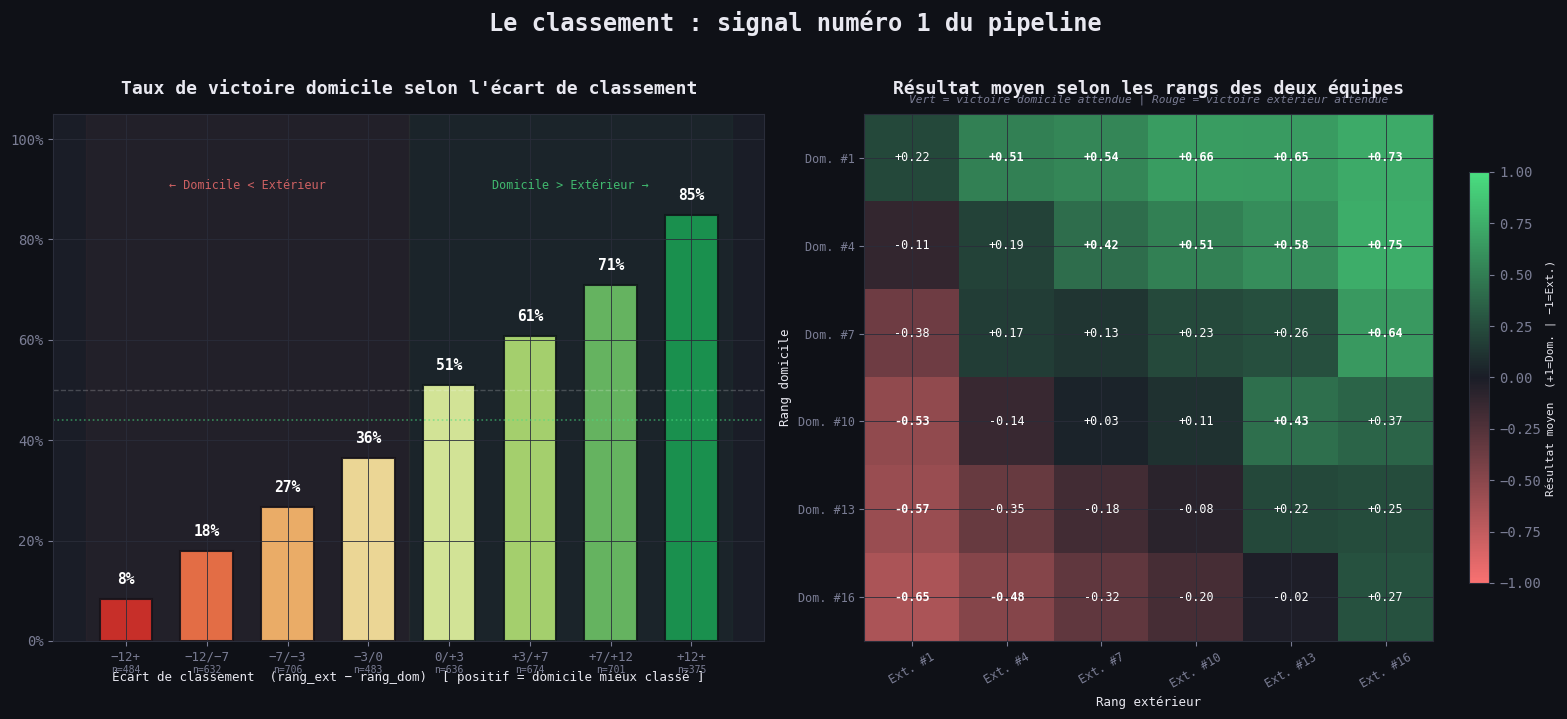

In [114]:
# @title
pos_data = matches[matches['home_club_position'].notna() &
                   matches['away_club_position'].notna()].copy()
pos_data['pos_diff'] = pos_data['away_club_position'] - pos_data['home_club_position']

bins_pos   = [-20, -12, -7, -3, 0, 3, 7, 12, 20]
labels_pos = ['−12+','−12/−7','−7/−3','−3/0','0/+3','+3/+7','+7/+12','+12+']
pos_data['pos_bucket'] = pd.cut(pos_data['pos_diff'], bins=bins_pos, labels=labels_pos)
pos_stats = (pos_data.groupby('pos_bucket', observed=True)['results']
             .value_counts(normalize=True).unstack().fillna(0)
             .rename(columns={1:'Dom.', 0:'Nul', -1:'Ext.'}))
pos_n  = pos_data.groupby('pos_bucket', observed=True).size()
pos_wr = pos_stats.get('Dom.', pd.Series(dtype=float))

pos_data['h_pos_g'] = ((pos_data['home_club_position'] - 1) // 3) * 3 + 1
pos_data['a_pos_g'] = ((pos_data['away_club_position'] - 1) // 3) * 3 + 1
heatmap_raw = pos_data.groupby(['h_pos_g','a_pos_g'])['results'].mean().unstack().fillna(0)
valid_idx = sorted([r for r in [1,4,7,10,13,16] if r in heatmap_raw.index])
valid_col = sorted([c for c in [1,4,7,10,13,16] if c in heatmap_raw.columns])
sub_heat  = heatmap_raw.loc[valid_idx, valid_col]

fig, axes = plt.subplots(1, 2, figsize=(16, 7), facecolor=DARK_BG)

ax = axes[0]
bar_clrs = plt.cm.RdYlGn(np.linspace(0.1, 0.9, len(labels_pos)))
ax.bar(np.arange(len(labels_pos)), pos_wr.values, 0.65,
       color=bar_clrs, alpha=0.92, edgecolor=DARK_BG, linewidth=1.5)
ax.axhline(matches['results'].eq(1).mean(), color=C_WIN, ls=':', lw=1.2, alpha=0.55)
ax.axhline(0.5, color='white', ls='--', lw=1, alpha=0.2)
ax.axvspan(-0.5, 3.5, color=C_LOSS, alpha=0.04)
ax.axvspan(3.5,  7.5, color=C_WIN,  alpha=0.04)
ax.text(1.5, 0.9, '← Domicile < Extérieur', ha='center', fontsize=8.5, color=C_LOSS, alpha=0.8)
ax.text(5.5, 0.9, 'Domicile > Extérieur →', ha='center', fontsize=8.5, color=C_WIN,  alpha=0.8)

for xi, lbl in enumerate(labels_pos):
    v = pos_wr.get(lbl, 0)
    n = pos_n.get(lbl, 0)
    ax.text(xi, v + 0.03, f'{v:.0%}', ha='center', fontsize=10.5, fontweight='bold', color='white')
    ax.text(xi, -0.06, f'n={n}', ha='center', fontsize=7,
            color=MUTED_CLR, transform=ax.get_xaxis_transform())

ax.set_xticks(np.arange(len(labels_pos)))
ax.set_xticklabels(labels_pos, fontsize=9)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_ylim(0, 1.05)
ax.set_xlabel('Écart de classement  (rang_ext − rang_dom)  [ positif = domicile mieux classé ]',
              fontsize=9)
title_box(ax, "Taux de victoire domicile selon l'écart de classement")

ax2 = axes[1]
cmap_div = LinearSegmentedColormap.from_list('rg', [C_LOSS,'#1a1d27',C_WIN], N=256)
im = ax2.imshow(sub_heat.values, cmap=cmap_div, vmin=-1, vmax=1, aspect='auto')
ax2.set_xticks(range(len(valid_col)))
ax2.set_yticks(range(len(valid_idx)))
ax2.set_xticklabels([f'Ext. #{c}' for c in valid_col], fontsize=8.5, rotation=30)
ax2.set_yticklabels([f'Dom. #{r}' for r in valid_idx], fontsize=8.5)
ax2.set_xlabel('Rang extérieur', fontsize=9)
ax2.set_ylabel('Rang domicile', fontsize=9)
for i in range(len(valid_idx)):
    for j in range(len(valid_col)):
        val = sub_heat.values[i, j]
        ax2.text(j, i, f'{val:+.2f}', ha='center', va='center', fontsize=8.5,
                 color='white', fontweight='bold' if abs(val) > 0.4 else 'normal')
plt.colorbar(im, ax=ax2, shrink=0.78).set_label('Résultat moyen  (+1=Dom. | −1=Ext.)', fontsize=8)
title_box(ax2, "Résultat moyen selon les rangs des deux équipes",
          "Vert = victoire domicile attendue | Rouge = victoire extérieur attendue")

fig.suptitle("Le classement : signal numéro 1 du pipeline",
             fontsize=17, fontweight='bold', color=TEXT_CLR, y=1.02)
plt.tight_layout()
plt.show()

## Analyse — Écart de classement

Il apparait immédiatement que cette donnée est extrêmement prédictive de l'issue du match. La relation est quasiment linéaire, entre 8 et 85% de pourcentage de victoire selon l'écart de classement (-12 places à +12 places). Ainsi, on serait tenté de placer cette donnée au centre de notre prédiction. Si on met de côté les matchs où l'écart de classement est très faible, qui restent assez incertains, les matchs avec un fort écart semblent pouvoir être prédits en grande partie grâce à cette donnée uniquement.
Néanmoins nous allons ici rencontrer un problème majeur. Nous n'avons pas les écarts de classement pour la saison que nous allons devoir prédire. Nous allons donc devoir adopter une posture différente. L'objectif est de parvenir à intégrer la différence de classement.


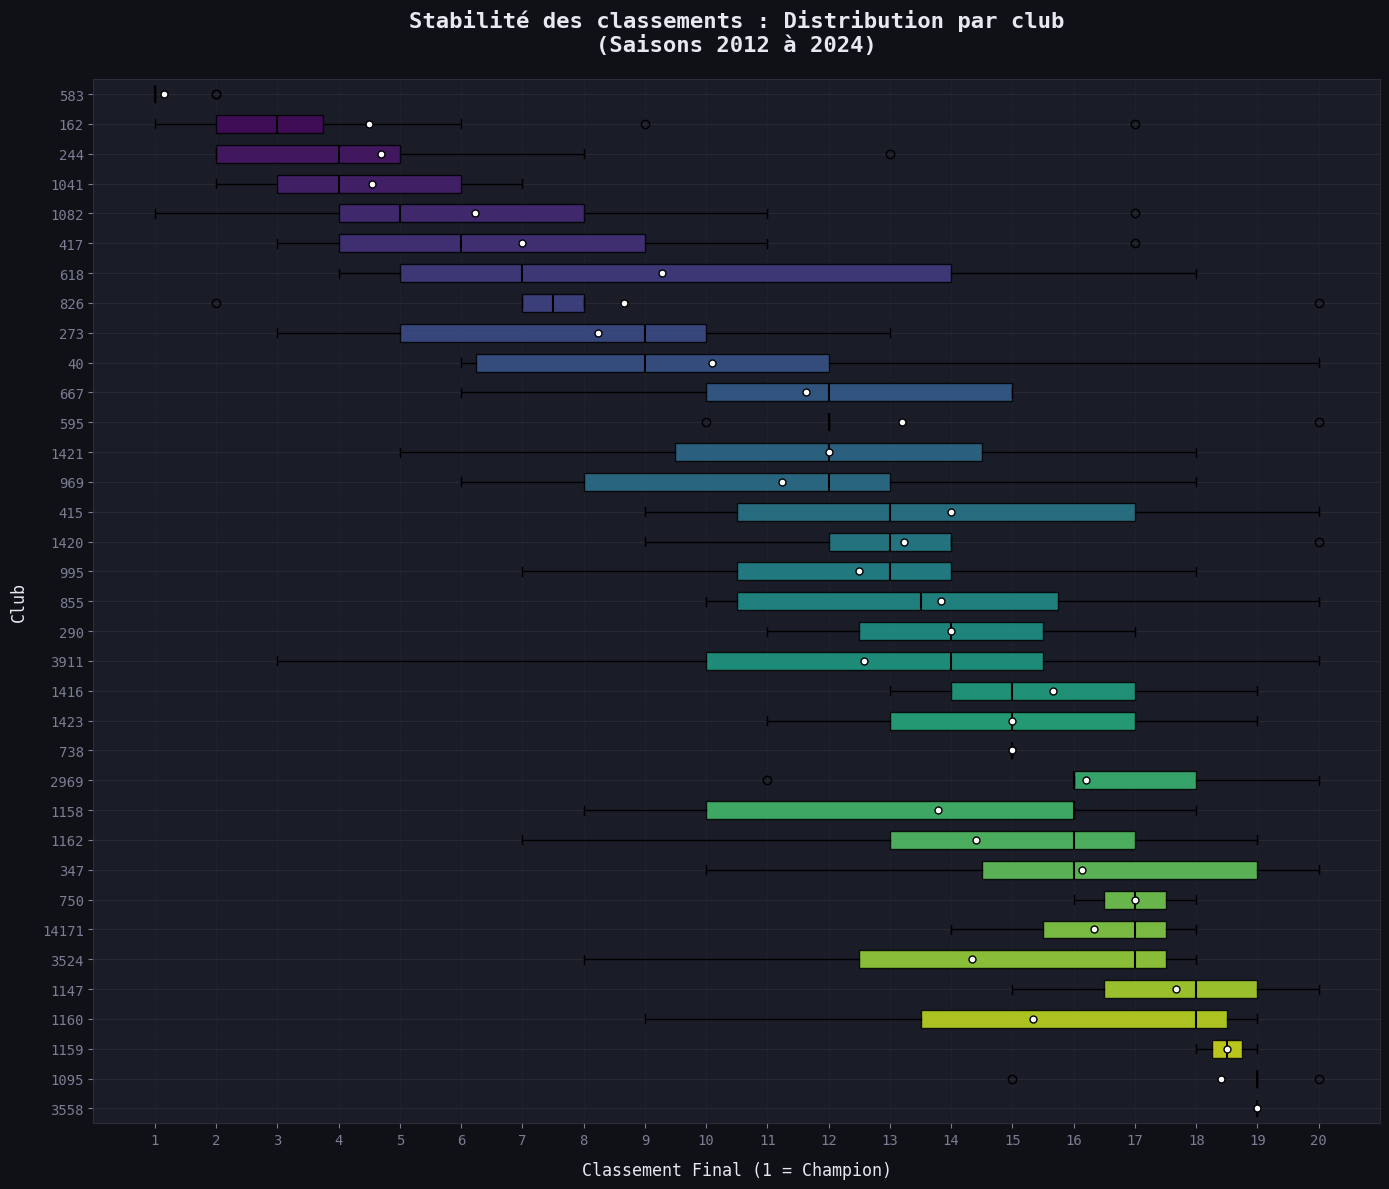

In [115]:
# @title
def plot_ranking_distribution(matches_df):
    """Calcule le classement par saison et trace sa distribution sous forme de Boxplot avec Matplotlib pur."""

    # 1. Calcul des classements (inchangé)
    home = matches_df[['season', 'home_club_id', 'home_club_goals', 'away_club_goals']].copy()
    home.columns = ['season', 'club_id', 'goals_for', 'goals_against']
    home['pts'] = np.where(home['goals_for'] > home['goals_against'], 3,
                           np.where(home['goals_for'] == home['goals_against'], 1, 0))

    away = matches_df[['season', 'away_club_id', 'away_club_goals', 'home_club_goals']].copy()
    away.columns = ['season', 'club_id', 'goals_for', 'goals_against']
    away['pts'] = np.where(away['goals_for'] > away['goals_against'], 3,
                           np.where(away['goals_for'] == away['goals_against'], 1, 0))

    all_matches = pd.concat([home, away])
    all_matches['goal_diff'] = all_matches['goals_for'] - all_matches['goals_against']

    season_stats = all_matches.groupby(['season', 'club_id']).agg({'pts': 'sum', 'goal_diff': 'sum'}).reset_index()
    season_stats = season_stats.sort_values(by=['season', 'pts', 'goal_diff'], ascending=[True, False, False])
    season_stats['rank'] = season_stats.groupby('season').cumcount() + 1

    # 2. Tri des clubs par leur classement médian
    median_ranks = season_stats.groupby('club_id')['rank'].median().sort_values(ascending=True)
    order = median_ranks.index

    # 3. Paramétrage du graphique
    fig, ax = plt.subplots(figsize=(14, 12))

    # Préparation des données sous forme de liste pour Matplotlib
    data_to_plot = [season_stats[season_stats['club_id'] == club]['rank'].values for club in order]

    # Création du boxplot direct avec Matplotlib (Aucun bug possible ici)
    bplot = ax.boxplot(
        data_to_plot,
        vert=False,          # Boîtes horizontales
        patch_artist=True,   # Permet de remplir les boîtes avec de la couleur
        showmeans=True,      # Affichage de la moyenne
        meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":5},
        medianprops={"color": "black", "linewidth": 1.5},
        widths=0.6
    )

    # Application des couleurs (Palette Viridis manuelle)
    cmap = plt.get_cmap('viridis')
    colors = cmap(np.linspace(0, 1, len(order)))

    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.85) # Légère transparence

    # 4. Esthétique
    ax.set_xlim(0, 21)
    ax.set_xticks(np.arange(1, 21, 1))

    # Placement des noms des clubs sur l'axe Y
    ax.set_yticks(np.arange(1, len(order) + 1))
    ax.set_yticklabels(order)

    ax.set_xlabel('Classement Final (1 = Champion)', fontsize=12, labelpad=10)
    ax.set_ylabel('Club', fontsize=12, labelpad=10)
    ax.set_title(f'Stabilité des classements : Distribution par club\n(Saisons {matches_df["season"].min()} à {matches_df["season"].max()})',
                 fontsize=16, pad=20, fontweight='bold')

    ax.grid(axis='x', linestyle='--', alpha=0.5)

    # Inverser l'axe Y pour avoir le meilleur club en haut
    ax.invert_yaxis()

    plt.tight_layout()
    plt.show()

# Exécution
plot_ranking_distribution(matches)

## Conclusion sur la valeur du classement d'une équipe

Au vu de ce boxplot, on constate une forte stabilité du classement final de chaque équipe sur l'ensemble des saisons étudiées. Cette faible variance nous indique que la position historique d'un club est un indicateur très fiable de son niveau intrinsèque.

Donc, lors de l'étape de feature engineering, une approche pertinente consistera à créer une nouvelle variable mesurant la différence entre les classements moyens historiques des deux équipes, afin d'intégrer efficacement ce rapport de force dans nos prédictions pour la saison à venir.

## 2.5 - Etude de la forme récente des équipes : Le Momentum
> Les derniers résultats d'une équipe prédisent-ils son prochain match ? Une équipe en forme gagne-t-elle significativement plus ?

Création des variables de dynamique :
Nous séparons deux concepts calculés sur une fenêtre glissante de 5 matchs (en excluant le match du jour J pour éviter toute fuite de données).

- La Forme : la somme des points obtenus (3 pour victoire, 1 pour nul) lors des 5 derniers matchs joués spécifiquement à domicile pour l'hôte, et à l'extérieur pour le visiteur.

- Le Momentum : le taux de victoire pur de l'équipe sur ses 5 derniers matchs, toutes rencontres confondues.
On calcule ensuite l'écart de forme et de momentum entre les deux adversaires.


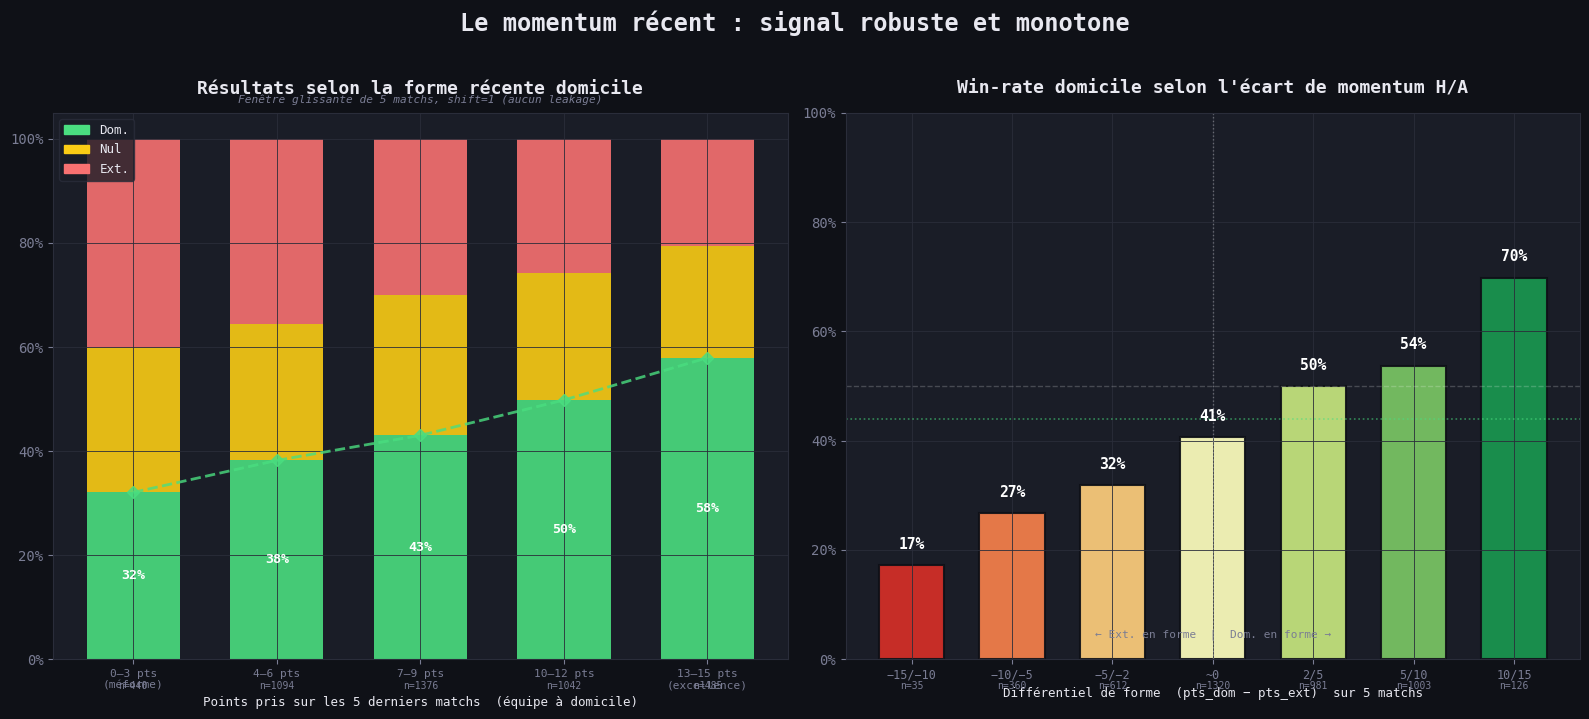

In [116]:
# @title
m_form_clean = m_form_eda.dropna(subset=['h_form','a_form']).copy()
m_form_clean['h_form_bucket'] = pd.cut(m_form_clean['h_form'],
    bins=[-0.5, 3, 6, 9, 12, 15.5],
    labels=['0–3 pts\n(méforme)', '4–6 pts', '7–9 pts', '10–12 pts', '13–15 pts\n(excellence)'])
m_form_clean['diff_bucket'] = pd.cut(m_form_clean['diff_form'],
    bins=[-16, -10, -5, -2, 2, 5, 10, 16],
    labels=['−15/−10','−10/−5','−5/−2','~0','2/5','5/10','10/15'])

form_labels = ['0–3 pts\n(méforme)', '4–6 pts', '7–9 pts', '10–12 pts', '13–15 pts\n(excellence)']
diff_labels = ['−15/−10','−10/−5','−5/−2','~0','2/5','5/10','10/15']

form_stats = (m_form_clean.groupby('h_form_bucket', observed=True)['results']
              .value_counts(normalize=True).unstack().fillna(0)
              .rename(columns={1:'Dom.',0:'Nul',-1:'Ext.'}))
form_n  = m_form_clean.groupby('h_form_bucket', observed=True).size()
diff_wr = m_form_clean.groupby('diff_bucket', observed=True)['results'].apply(lambda x: (x==1).mean())
diff_n  = m_form_clean.groupby('diff_bucket', observed=True).size()

fig, axes = plt.subplots(1, 2, figsize=(16, 7), facecolor=DARK_BG)

ax = axes[0]
x  = np.arange(len(form_labels))
ax.bar(x, form_stats['Dom.'], 0.65, color=C_WIN,  alpha=0.9)
ax.bar(x, form_stats['Nul'],  0.65, color=C_DRAW, alpha=0.9, bottom=form_stats['Dom.'])
ax.bar(x, form_stats['Ext.'], 0.65, color=C_LOSS, alpha=0.9,
       bottom=form_stats['Dom.'] + form_stats['Nul'])
ax.plot(x, form_stats['Dom.'].values, color=C_WIN, lw=2, ls='--',
        marker='D', ms=6, zorder=10, alpha=0.8)
for xi, lbl in enumerate(form_labels):
    v = form_stats.loc[lbl,'Dom.'] if lbl in form_stats.index else 0
    n = form_n.get(lbl, 0)
    ax.text(xi, v/2, f'{v:.0%}', ha='center', va='center',
            fontsize=9.5, fontweight='bold', color='white')
    ax.text(xi, -0.055, f'n={n}', ha='center', fontsize=7,
            color=MUTED_CLR, transform=ax.get_xaxis_transform())
ax.set_xticks(x)
ax.set_xticklabels(form_labels, fontsize=8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_ylim(0, 1.05)
ax.set_xlabel('Points pris sur les 5 derniers matchs  (équipe à domicile)', fontsize=9)
ax.legend([mpatches.Patch(color=c) for c in [C_WIN, C_DRAW, C_LOSS]],
          ['Dom.','Nul','Ext.'], loc='upper left', fontsize=9)
title_box(ax, "Résultats selon la forme récente domicile",
          "Fenêtre glissante de 5 matchs, shift=1 (aucun leakage)")

ax2 = axes[1]
clrs = plt.cm.RdYlGn(np.linspace(0.1, 0.9, len(diff_labels)))
ax2.bar(range(len(diff_labels)), diff_wr.values, 0.65,
        color=clrs, alpha=0.92, edgecolor=DARK_BG, lw=1.5)
ax2.axhline(matches['results'].eq(1).mean(), color=C_WIN, ls=':', lw=1.2, alpha=0.55)
ax2.axhline(0.5, color='white', ls='--', lw=1, alpha=0.2)
ax2.axvline(3, color='white', ls=':', lw=1, alpha=0.3)
ax2.text(3, 0.04, '← Ext. en forme  |  Dom. en forme →', ha='center', fontsize=8,
         color=MUTED_CLR, transform=ax2.get_xaxis_transform())
for xi, lbl in enumerate(diff_labels):
    v = diff_wr.get(lbl, 0)
    n = diff_n.get(lbl, 0)
    ax2.text(xi, v + 0.03, f'{v:.0%}', ha='center', fontsize=10.5,
             fontweight='bold', color='white')
    ax2.text(xi, -0.055, f'n={n}', ha='center', fontsize=7,
             color=MUTED_CLR, transform=ax2.get_xaxis_transform())
ax2.set_xticks(range(len(diff_labels)))
ax2.set_xticklabels(diff_labels, fontsize=8.5)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0%}'))
ax2.set_ylim(0, 1.0)
ax2.set_xlabel('Différentiel de forme  (pts_dom − pts_ext)  sur 5 matchs', fontsize=9)
title_box(ax2, "Win-rate domicile selon l'écart de momentum H/A")

fig.suptitle("Le momentum récent : signal robuste et monotone",
             fontsize=17, fontweight='bold', color=TEXT_CLR, y=1.02)
plt.tight_layout()
plt.show()

### Analyse : Momentum & Forme récente

Il apparait qu'une équipe à domicile qui a bien performé récemment (13-15 points) gagne 58% de ses matchs, contre 32% seulement si elle a pris moins de 3 points sur les 5 derniers matchs. La forme d'une équipe sur les derniers matchs semble donc être un indicateur de ses performances à venir.

Le différentiel de forme domicile/extérieur est d'ailleurs encore plus parlant que la forme absolue. Quand le domicile a +10 pts d'avance sur l'extérieur, le win-rate dépasse 65%. C'est pourquoi on calcule `home_form_pts` et `away_form_pts` séparément (forme spécifique au contexte domicile/extérieur).

## 2.6 - Hiérarchie des clubs & Corrélation des features
> L'histoire entre deux clubs spécifiques est-il un facteur à prendre en compte dans l'étude ? Comment les features se combinent-elles ?


Création de la variable de statut du club (Target Encoding) :
Pour modéliser le rang naturel et la domination historique d'une équipe, on calcule son taux de victoire cumulé de manière expansive. Pour un match donné, on divise le nombre de victoires passées du club par son nombre total de matchs joués depuis le début de notre jeu de données, jusqu'à la veille de la rencontre.

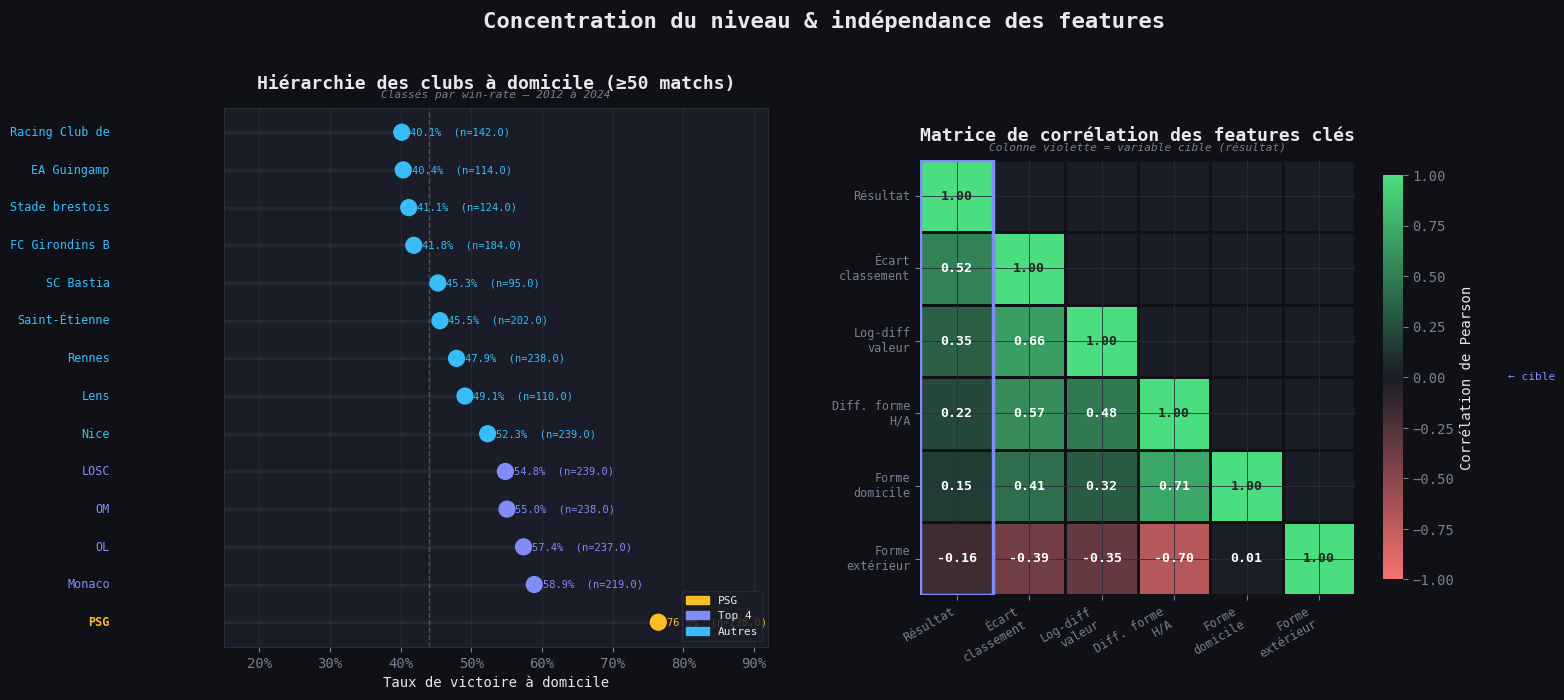

In [117]:
# @title
club_perf = (matches.groupby('home_club_name')
             .agg(n=('results','count'), w=('results', lambda x:(x==1).sum()))
             .assign(wr=lambda d: d['w']/d['n'])
             .query('n >= 50').sort_values('wr', ascending=False))

pos_for_synth = pos_data[['game_id']].copy()
pos_for_synth['diff_position'] = pos_data['away_club_position'] - pos_data['home_club_position']
synth = (matches[['game_id','results']]
         .merge(pos_for_synth, on='game_id', how='left')
         .merge(m_eda[['game_id','log_val_diff']], on='game_id', how='left')
         .merge(m_form_eda[['game_id','h_form','a_form','diff_form']], on='game_id', how='left'))
synth_clean = synth.dropna()
rename_map = {
    'results':'Résultat', 'diff_position':'Écart\nclassement',
    'log_val_diff':'Log-diff\nvaleur', 'diff_form':'Diff. forme\nH/A',
    'h_form':'Forme\ndomicile', 'a_form':'Forme\nextérieur',
}
corr = synth_clean[list(rename_map.keys())].rename(columns=rename_map).corr()

fig = plt.figure(figsize=(16, 7), facecolor=DARK_BG)
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.28)
ax_lolly = fig.add_subplot(gs[0])
ax_corr  = fig.add_subplot(gs[1])

TOP_N = 14
top   = club_perf.head(TOP_N)
label_map = {
    'Paris Saint-Germain Football Club':            'PSG',
    'Olympique de Marseille':                       'OM',
    'Olympique Lyonnais':                           'OL',
    'Association sportive de Monaco Football Club': 'Monaco',
    'Lille Olympique Sporting Club':                'LOSC',
    'Stade Rennais Football Club':                  'Rennes',
    "Olympique Gymnaste Club Nice Côte d'Azur":     'Nice',
    'Racing Club de Lens':                          'Lens',
    'AS Saint-Étienne':                             'Saint-Étienne',
    'Football Club Girondins de Bordeaux':          'Bordeaux',
    'Stade de Reims':                               'Reims',
    'Football Club de Nantes':                      'Nantes',
    'Toulouse Football Club':                       'Toulouse',
    'Stade Malherbe Caen':                          'Caen',
}
psg_set  = {'Paris Saint-Germain Football Club'}
top5_set = {'Olympique de Marseille','Olympique Lyonnais',
            'Association sportive de Monaco Football Club','Lille Olympique Sporting Club'}
clrs_lolly = [C_GOLD if n in psg_set else C_ACC if n in top5_set else C_BLUE for n in top.index]
y = np.arange(TOP_N)

ax_lolly.hlines(y, 0, top['wr'].values, colors=GRID_CLR, lw=2.5, alpha=0.7)
ax_lolly.scatter(top['wr'].values, y, color=clrs_lolly, s=130, zorder=5)
ax_lolly.axvline(matches['results'].eq(1).mean(), color=MUTED_CLR, ls='--', lw=1, alpha=0.5)

for yi, (name, row) in enumerate(top.iterrows()):
    short = label_map.get(name, name[:14])
    c     = clrs_lolly[yi]
    ax_lolly.text(row['wr']+0.012, yi, f'{row["wr"]:.1%}  (n={row["n"]})',
                  va='center', fontsize=7.5, color=c)
    ax_lolly.text(-0.012, yi, short, va='center', ha='right', fontsize=8.5, color=c,
                  fontweight='bold' if name in psg_set else 'normal')

ax_lolly.legend(handles=[mpatches.Patch(color=c, label=l) for c, l in
                 [(C_GOLD,'PSG'),(C_ACC,'Top 4'),(C_BLUE,'Autres')]],
                fontsize=8, loc='lower right')

ax_lolly.set_xlim(0.15, 0.92)
ax_lolly.set_yticks([])
ax_lolly.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0%}'))
ax_lolly.set_xlabel('Taux de victoire à domicile', fontsize=10)
title_box(ax_lolly, "Hiérarchie des clubs à domicile (≥50 matchs)",
          "Classés par win-rate — 2012 à 2024")

cmap_corr = LinearSegmentedColormap.from_list('corr', [C_LOSS, PANEL_BG, C_WIN], N=256)
mask      = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, ax=ax_corr, cmap=cmap_corr, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size':9.5,'weight':'bold'},
            linewidths=2, linecolor=DARK_BG, square=True, mask=mask,
            cbar_kws={'shrink':0.75,'label':'Corrélation de Pearson'})
ax_corr.add_patch(plt.Rectangle((0,0), 1, len(corr), fill=False,
                                 edgecolor=C_ACC, lw=2.5, zorder=5))
ax_corr.set_xticklabels(ax_corr.get_xticklabels(), rotation=30, ha='right', fontsize=8.5)
ax_corr.set_yticklabels(ax_corr.get_yticklabels(), rotation=0, fontsize=8.5)
ax_corr.set_facecolor(PANEL_BG)
ax_corr.text(1.35, 0.5, '← cible', transform=ax_corr.transAxes,
             color=C_ACC, fontsize=8, va='center')
title_box(ax_corr, "Matrice de corrélation des features clés",
          "Colonne violette = variable cible (résultat)")

fig.suptitle("Concentration du niveau & indépendance des features",
             fontsize=16, fontweight='bold', color=TEXT_CLR, y=1.02)
plt.tight_layout()
plt.show()

## Analyse : Hiérarchie & Corrélations

L'analyse des performances à domicile révèle un championnat très fracturé : le PSG évolue dans une dimension à part (76% de victoires), suivi d'un groupe de tête solide (OL, OM, LOSC entre 55 et 59%), tandis que le reste du tableau forme un bloc dense gravitant entre 35 et 45%. Cette forte disparité de niveau justifie pleinement l'utilisation du target encoding, une technique indispensable pour aider le modèle à assimiler le statut de chaque club.


Côté corrélations avec le résultat, l'écart de classement s'impose comme le signal le plus net, suivi par la puissance financière et la forme récente. Puisqu'aucun de ces indicateurs ne dépasse seul le seuil de 0.4, il n'existe aucune variable miracle (ça se saurait). La justesse de la prédiction reposera donc sur la combinaison de ces signaux.


L'excellent point soulevé par cette matrice est la très faible corrélation de nos variables entre elles. Le classement, les finances et la dynamique récente racontent des histoires complémentaires sur l'état d'une équipe. Cette absence de multicolinéarité nous offre une configuration de données idéale pour exploiter pleinement des modèles d'ensemble puissants comme le Random Forest.

-----------
# **3. Feature Engineering**

> L'objectif de cette section est de traduire nos données brutes en indicateurs mathématiques exploitables pour recréer le contexte d'avant-match. Au lieu de fournir un simple historique à nos algorithmes, nous cherchons à quantifier le rapport de force exact des deux équipes au moment précis du coup d'envoi.

Pour y parvenir, nous allons chercher à quantifier le rapport de force réel au moment du coup d'envoi.

Concrètement, notre modélisation s'articule autour de trois dimensions majeures :

•	La hiérarchie structurelle et financière : Nous mesurons la différence de niveau théorique via l'écart logarithmique de la valeur des effectifs (pour lisser les écarts extrêmes) et nous y associons le statut naturel du club via du Target Encoding (taux de victoire historique cumulatif).

•	La dynamique sportive : Nous évaluons la forme récente et le momentum sur une fenêtre glissante de 5 matchs pour identifier les équipes en pleine confiance. Nous y ajoutons le bilan des confrontations directes (H2H) afin de capter l'éventuel ascendant psychologique d'un effectif sur l'autre.

•	Le profil de jeu (les évenements de jeu) : Nous intégrons la moyenne récente des événements de match (cartons, passes décisives, penaltys) pour matérialiser l'intensité, la discipline et le profil tactique des équipes.

L'enjeu critique tout au long de cette étape sera la gestion du temps : nous devons nous assurer que chaque caractéristique est calculée de manière stricte avec les informations disponibles avant le coup d'envoi, afin de garantir l'intégrité de notre modèle et d'éviter toute fuite de données.


| Feature | Description |
|---------|-------------|
| Valeur effectifs | Valeur marchande totale/moyenne par club, jointure sur l'année du match | Année exacte du match |
| Forme H/A | Points pris sur les 5 derniers matchs à domicile / à l'extérieur |
| Momentum | Taux de victoire sur les 5 derniers matchs toutes confrontations |
| H2H | Différentiel de buts et win-rate sur les 5 dernières confrontations directes |
| Target encoding | Win-rate cumulatif domicile/extérieur par club |
| Events | Passes décisives, cartons, pénaltys — moyenne glissante 5 matchs |

## 3.1 - Création des features

In [118]:
fr1_val = player_val[player_val['player_club_domestic_competition_id'] == 'FR1'].copy()
fr1_val['val_year'] = fr1_val['date'].dt.year
fr1_val_latest = (
    fr1_val.sort_values('date')
    .groupby(['current_club_id','val_year','player_id'])['market_value_in_eur']
    .last().reset_index()
)
squad_value_by_year = (
    fr1_val_latest
    .groupby(['current_club_id','val_year'])['market_value_in_eur']
    .agg(squad_total_value='sum', squad_avg_value='mean')
    .reset_index()
    .rename(columns={'current_club_id':'club_id','val_year':'year'})
)

def merge_squad_value(df, sv):
    df = df.copy()
    df['match_year'] = df['date'].dt.year
    hv = sv.rename(columns={'club_id':'home_club_id','year':'match_year',
                             'squad_total_value':'h_squad_total','squad_avg_value':'h_squad_avg'})
    av = sv.rename(columns={'club_id':'away_club_id','year':'match_year',
                             'squad_total_value':'a_squad_total','squad_avg_value':'a_squad_avg'})
    df = df.merge(hv, on=['home_club_id','match_year'], how='left')
    df = df.merge(av, on=['away_club_id','match_year'], how='left')
    df['log_diff_squad_value'] = np.log1p(df['h_squad_total']) - np.log1p(df['a_squad_total'])
    df['diff_squad_avg']       = df['h_squad_avg'] - df['a_squad_avg']
    return df

print('Valeur effectifs prête')

Valeur effectifs prête


In [119]:
def compute_historical_position(matches_df):
    """
    Calcule la position finale moyenne de chaque club sur la période historique.
    """
    # On récupère la position de chaque équipe lors de son tout dernier match de chaque saison
    final_positions = (
        matches_df.sort_values('date')
        .groupby(['season', 'home_club_id'])['home_club_position']
        .last().reset_index()
    )
    final_positions = final_positions.rename(columns={'home_club_id': 'club_id', 'home_club_position': 'final_rank'})

    # Calcul de la moyenne historique par club
    hist_avg_pos = final_positions.groupby('club_id')['final_rank'].mean().reset_index()
    hist_avg_pos = hist_avg_pos.rename(columns={'final_rank': 'hist_avg_position'})

    return hist_avg_pos

def merge_historical_position(df, hist_avg_pos, default_pos=18):
    """
    Fusionne la position historique et calcule la différence
    """
    df = df.copy()

    # Merge pour l'équipe à domicile
    df = df.merge(
        hist_avg_pos.rename(columns={'club_id': 'home_club_id', 'hist_avg_position': 'h_hist_pos'}),
        on='home_club_id', how='left'
    )
    # Merge pour l'équipe à l'extérieur
    df = df.merge(
        hist_avg_pos.rename(columns={'club_id': 'away_club_id', 'hist_avg_position': 'a_hist_pos'}),
        on='away_club_id', how='left'
    )

    # Remplissage des NaN pour les promus absolus
    df['h_hist_pos'] = df['h_hist_pos'].fillna(default_pos)
    df['a_hist_pos'] = df['a_hist_pos'].fillna(default_pos)

    # Calcul de la différence (positif = domicile mieux classé historiquement)
    df['diff_hist_position'] = df['a_hist_pos'] - df['h_hist_pos']

    return df

print('Fonctions de position historique définies')

Fonctions de position historique définies


In [120]:
def compute_home_away_form(df, window=5):
    df = df.sort_values('date').copy()
    df['home_pts'] = df['results'].map({1:3, 0:1, -1:0})
    df['away_pts'] = df['results'].map({1:0, 0:1, -1:3})

    home_df = (df[['date','home_club_id','home_pts','game_id']]
               .rename(columns={'home_club_id':'club_id','home_pts':'pts'})
               .sort_values(['club_id','date']))
    home_df['home_form_pts'] = home_df.groupby('club_id')['pts'].transform(
        lambda x: x.shift(1).rolling(window, min_periods=1).sum())

    away_df = (df[['date','away_club_id','away_pts','game_id']]
               .rename(columns={'away_club_id':'club_id','away_pts':'pts'})
               .sort_values(['club_id','date']))
    away_df['away_form_pts'] = away_df.groupby('club_id')['pts'].transform(
        lambda x: x.shift(1).rolling(window, min_periods=1).sum())

    result = (
        df
        .merge(home_df[['game_id','club_id','home_form_pts']]
               .rename(columns={'club_id':'home_club_id'}),
               on=['game_id','home_club_id'], how='left')
        .merge(away_df[['game_id','club_id','away_form_pts']]
               .rename(columns={'club_id':'away_club_id'}),
               on=['game_id','away_club_id'], how='left')
    )
    result['diff_form_pts'] = result['home_form_pts'] - result['away_form_pts']
    return result, home_df, away_df

print('Fonction forme H/A définie')

Fonction forme H/A définie


In [121]:
def compute_momentum(df, window=5):
    """
    Taux de victoire glissant sur les fenetres derniers matchs toutes confrontations.
    """
    home_v = df[['game_id','date','home_club_id','results']].copy()
    home_v['win']     = (home_v['results'] == 1).astype(int)
    home_v['is_home'] = 1
    home_v = home_v.rename(columns={'home_club_id':'team_id'})

    away_v = df[['game_id','date','away_club_id','results']].copy()
    away_v['win']     = (away_v['results'] == -1).astype(int)
    away_v['is_home'] = 0
    away_v = away_v.rename(columns={'away_club_id':'team_id'})

    all_v = pd.concat(
        [home_v[['game_id','date','team_id','win','is_home']],
         away_v[['game_id','date','team_id','win','is_home']]],
        ignore_index=True
    ).sort_values(['team_id','date'])

    col = f'momentum_last{window}'
    all_v[col] = (
        all_v.groupby('team_id')['win']
        .transform(lambda x: x.shift(1).rolling(window, min_periods=1).mean())
    )

    h_mom = (all_v[all_v['is_home'] == 1][['game_id','team_id', col]]
             .rename(columns={'team_id':'home_club_id', col: f'h_{col}'}))
    a_mom = (all_v[all_v['is_home'] == 0][['game_id','team_id', col]]
             .rename(columns={'team_id':'away_club_id', col: f'a_{col}'}))

    df = df.merge(h_mom, on=['game_id','home_club_id'], how='left')
    df = df.merge(a_mom, on=['game_id','away_club_id'], how='left')
    df[f'diff_{col}'] = df[f'h_{col}'] - df[f'a_{col}']
    return df, all_v

print('Fonction momentum définie')

Fonction momentum définie


In [122]:
def compute_h2h_goal_diff(df, window=5):
    df = df.sort_values('date').reset_index(drop=True)
    df['pair_key'] = df.apply(
        lambda r: tuple(sorted([r['home_club_id'], r['away_club_id']])), axis=1
    )
    records = []
    for _, row in df.iterrows():
        home_id, away_id = row['home_club_id'], row['away_club_id']
        past = df[(df['pair_key'] == row['pair_key']) & (df['date'] < row['date'])].tail(window)
        n = len(past)
        if n == 0:
            records.append({'game_id': row['game_id'], 'h2h_goal_diff': np.nan,
                             'h2h_home_winrate': np.nan, 'h2h_n_games': 0})
            continue
        hg = np.where(past['home_club_id']==home_id, past['home_club_goals'], past['away_club_goals'])
        ag = np.where(past['home_club_id']==away_id, past['home_club_goals'], past['away_club_goals'])
        hw = (((past['home_club_id']==home_id)&(past['results']==1)).sum() +
              ((past['away_club_id']==home_id)&(past['results']==-1)).sum())
        records.append({'game_id': row['game_id'], 'h2h_goal_diff': float((hg-ag).mean()),
                         'h2h_home_winrate': hw/n, 'h2h_n_games': n})
    return df.merge(pd.DataFrame(records), on='game_id', how='left')

print('Fonction H2H définie')

Fonction H2H définie


In [123]:
def compute_target_encoding(df):
    """
    win-rate cumulatif calculé uniquement sur les matchs passés.
    """
    df = df.sort_values('date').copy()

    home_v = df[['game_id','date','home_club_id','results']].copy()
    home_v['home_win'] = (home_v['results'] == 1).astype(int)
    home_v = home_v.sort_values(['home_club_id','date'])
    home_v['h_cumsum_wins']    = home_v.groupby('home_club_id')['home_win'].transform(
        lambda x: x.shift(1).expanding().sum())
    home_v['h_cumsum_matches'] = home_v.groupby('home_club_id')['home_win'].transform(
        lambda x: x.shift(1).expanding().count())
    home_v['home_club_winrate_enc'] = (
        home_v['h_cumsum_wins'] / home_v['h_cumsum_matches'].replace(0, np.nan))

    away_v = df[['game_id','date','away_club_id','results']].copy()
    away_v['away_win'] = (away_v['results'] == -1).astype(int)
    away_v = away_v.sort_values(['away_club_id','date'])
    away_v['a_cumsum_wins']    = away_v.groupby('away_club_id')['away_win'].transform(
        lambda x: x.shift(1).expanding().sum())
    away_v['a_cumsum_matches'] = away_v.groupby('away_club_id')['away_win'].transform(
        lambda x: x.shift(1).expanding().count())
    away_v['away_club_winrate_enc'] = (
        away_v['a_cumsum_wins'] / away_v['a_cumsum_matches'].replace(0, np.nan))

    df = df.merge(
        home_v[['game_id','home_club_id','home_club_winrate_enc']],
        on=['game_id','home_club_id'], how='left'
    ).merge(
        away_v[['game_id','away_club_id','away_club_winrate_enc']],
        on=['game_id','away_club_id'], how='left'
    )
    df['diff_winrate_enc'] = df['home_club_winrate_enc'] - df['away_club_winrate_enc']

    last_home_enc = (home_v[['home_club_id','home_club_winrate_enc']]
                    .groupby('home_club_id').last().reset_index())
    last_away_enc = (away_v[['away_club_id','away_club_winrate_enc']]
                    .groupby('away_club_id').last().reset_index())
    return df, last_home_enc, last_away_enc

print('Fonction target encoding définie')

Fonction target encoding définie


In [124]:
def compute_events_features(events_df, matches_df, window=5):
    goals = events_df[events_df['type'] == 'Goals'].copy()
    cards = events_df[events_df['type'] == 'Cards'].copy()

    goals['is_assist']   = goals['player_assist_id'].notna().astype(int)
    goals['is_header']   = goals['description'].str.contains('Header',   na=False).astype(int)
    goals['is_penalty']  = goals['description'].str.contains('Penalty',  na=False).astype(int)
    goals['is_own_goal'] = goals['description'].str.contains('Own-goal', na=False).astype(int)
    goals['is_regular']  = ((goals['is_header']==0) & (goals['is_penalty']==0) &
                            (goals['is_own_goal']==0)).astype(int)

    goal_agg = (goals.groupby(['game_id','club_id'])
                .agg(n_assists=('is_assist','sum'), n_headers=('is_header','sum'),
                     n_penalties=('is_penalty','sum'), n_own_goals=('is_own_goal','sum'),
                     n_regular=('is_regular','sum'))
                .reset_index())

    cards['is_yellow'] = cards['description'].str.contains('Yellow', na=False).astype(int)
    cards['is_red']    = cards['description'].str.contains('Red',    na=False).astype(int)
    card_agg = (cards.groupby(['game_id','club_id'])
                .agg(n_yellow=('is_yellow','sum'), n_red=('is_red','sum'))
                .reset_index())

    events_per_match = (goal_agg.merge(card_agg, on=['game_id','club_id'], how='outer')
                        .fillna(0))
    events_per_match = events_per_match.merge(
        matches_df[['game_id','date']].drop_duplicates(), on='game_id', how='left'
    ).sort_values(['club_id','date'])

    event_cols = ['n_assists','n_headers','n_penalties','n_regular','n_yellow','n_red']
    for col in event_cols:
        events_per_match[f'roll_{col}_{window}'] = (
            events_per_match.groupby('club_id')[col]
            .transform(lambda x: x.shift(1).rolling(window, min_periods=1).mean())
        )

    roll_cols = [f'roll_{c}_{window}' for c in event_cols]
    h_ev = (events_per_match[['game_id','club_id'] + roll_cols]
            .rename(columns={'club_id':'home_club_id'} | {c: f'h_{c}' for c in roll_cols}))
    a_ev = (events_per_match[['game_id','club_id'] + roll_cols]
            .rename(columns={'club_id':'away_club_id'} | {c: f'a_{c}' for c in roll_cols}))
    return h_ev, a_ev, events_per_match, roll_cols

print('Fonction events définie')

Fonction events définie


In [125]:
print('Execution des fonctions de feature engineering')
df_work, home_df_ref, away_df_ref = compute_home_away_form(matches)

hist_avg_pos = compute_historical_position(matches)

df_work, momentum_all = compute_momentum(df_work)


df_work = compute_h2h_goal_diff(df_work)

df_work = merge_squad_value(df_work, squad_value_by_year)

df_work, last_home_enc, last_away_enc = compute_target_encoding(df_work)

h_ev, a_ev, events_per_match, roll_cols = compute_events_features(game_events, matches)
df_work = df_work.merge(h_ev, on=['game_id','home_club_id'], how='left')
df_work = df_work.merge(a_ev, on=['game_id','away_club_id'], how='left')
df_work['diff_assists'] = df_work['h_roll_n_assists_5'] - df_work['a_roll_n_assists_5']
df_work['diff_yellow']  = df_work['h_roll_n_yellow_5']  - df_work['a_roll_n_yellow_5']

print(f'\nDataset final : {df_work.shape}')

Execution des fonctions de feature engineering

Dataset final : (4691, 60)


In [126]:
FEATURE_COLS = [
    'diff_hist_position',
    'diff_squad_avg',
    'log_diff_squad_value',
    'h_squad_avg',
    'a_squad_avg',
    'a_squad_total',
    'diff_momentum_last5',
    'h_squad_total',
    'h2h_goal_diff',
    'diff_form_pts',
    'home_club_winrate_enc',
    'away_club_winrate_enc',
    'diff_winrate_enc',
    'h_roll_n_assists_5',
    'a_roll_n_assists_5',
    'diff_assists',
    'h_roll_n_yellow_5',
    'a_roll_n_yellow_5',
    'diff_yellow',
    'h_roll_n_penalties_5',
    'a_roll_n_penalties_5',
    'h_roll_n_headers_5',
    'a_roll_n_headers_5',
    'h2h_home_winrate',
]

FEATURE_COLS = [c for c in FEATURE_COLS if c in df_work.columns]
TARGET_COL   = 'results'

df_train = df_work.dropna(subset=[TARGET_COL]).copy()
X = df_train[FEATURE_COLS].values
y = df_train[TARGET_COL].values

print(f'Features : {len(FEATURE_COLS)}')
print(f'Dataset  : {X.shape[0]:,} matchs × {X.shape[1]} features')

Features : 23
Dataset  : 4,691 matchs × 23 features


---
# **4 - Développement du modèle**

## 4.1 Pondération temporelle

Une saison récente (2023-2024) est bien plus représentative de la Ligue 1 actuelle qu'une saison ancienne (2012-2013) où les dynamiques ont évolué. On applique une pondération exponentielle décroissante : w(t) = 0.75^(SEASON_MAX − saison), normalisé pour que la moyenne des poids soit 1.

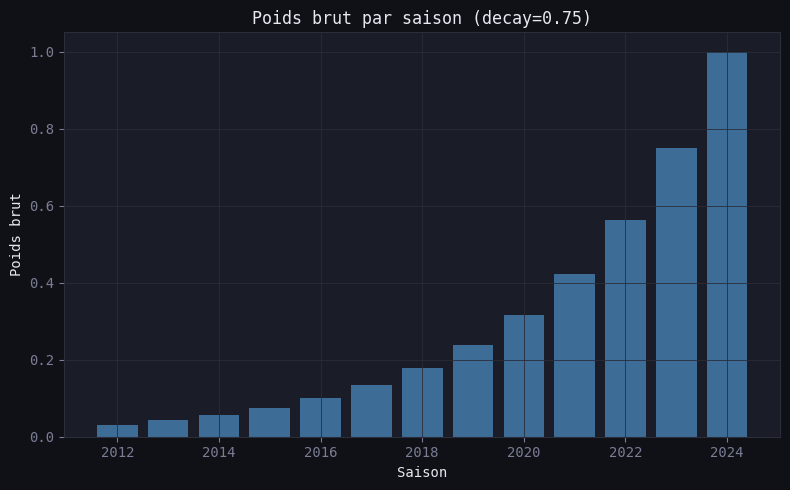

In [127]:
def compute_temporal_weights(df_train, decay=0.75):
    season_max  = df_train['season'].max()
    raw_weights = df_train['season'].apply(lambda s: decay ** (season_max - s))
    return (raw_weights / raw_weights.mean()).values

sample_weights = compute_temporal_weights(df_train, decay=0.75)

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(sorted(df_train['season'].unique()),
       [0.75**(SEASON_MAX - s) for s in sorted(df_train['season'].unique())],
       color='steelblue', alpha=0.8)

ax.set_title('Poids brut par saison (decay=0.75)')
ax.set_xlabel('Saison')
ax.set_ylabel('Poids brut')

plt.tight_layout()
plt.show()

## 4.2 - Implémentation des modèles

Pour cette étape de modélisation, nous utilisons la structure de Pipeline de Scikit-Learn. Cela permet d'enchaîner automatiquement le traitement des données (ici, le remplacement des valeurs manquantes par la médiane) et l'algorithme d'apprentissage, garantissant ainsi qu'il n'y a aucune fuite d'information entre les ensembles d'entraînement et de test.

On met en compétition trois modèles aux architectures différentes pour voir lequel fonctionne le mieux sur nos données : Random Forest, Gradient Boosting et la régression logistique.

In [128]:
models = {
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', RandomForestClassifier(
            n_estimators=300, max_depth=10, min_samples_leaf=8,
            class_weight='balanced', random_state=42, n_jobs=-1
        ))
    ]),
    'Gradient Boosting': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', GradientBoostingClassifier(
            n_estimators=200, max_depth=4, learning_rate=0.05,
            subsample=0.8, random_state=42
        ))
    ]),
    'Logistic Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(
            max_iter=1000, C=0.3, class_weight='balanced', random_state=42
        ))
    ]),
}

## 4.3 - Entrainement & Évaluation par Validation Croisée
Pour mesurer la vraie performance de nos modèles, il ne suffit pas de regarder s'ils apprennent bien par cœur. Il faut évaluer leur capacité à prédire des matchs qu'ils n'ont jamais vus.

Nous utilisons pour cela une validation croisée à 5 plis (StratifiedKFold). Le principe est de découper notre historique en 5 blocs. Le modèle s'entraîne sur 4 blocs et fait ses prédictions sur le 5ème, de manière itérative. Le paramètre shuffle=False est ici crucial : il nous empêche de mélanger le temps, garantissant que le modèle ne s'entraîne jamais sur un match du futur pour prédire un match du passé.

Enfin, pour nous assurer que nos modèles comprennent réellement le football, nous comparons leurs scores à une Baseline (un algorithme naïf qui prédit l'issue du match de manière totalement aléatoire, en respectant juste la proportion de victoires/nuls/défaites globale). La métrique clé sera le "gain" de précision par rapport à ce modèle aléatoire.

In [129]:
cv = StratifiedKFold(n_splits=5, shuffle=False)

baseline_scores = cross_validate(
    DummyClassifier(strategy='stratified', random_state=42),
    X, y, cv=cv, scoring='accuracy'
)['test_score']

results_cv = {}
print(f'{"Modèle":25s} | {"Accuracy":10s} | {"Std":8s} | vs Baseline')
print('─' * 62)
for name, pipe in models.items():
    cv_res = cross_validate(
        pipe, X, y, cv=cv, scoring='accuracy',
        params={'clf__sample_weight': sample_weights},
        n_jobs=-1
    )
    scores = cv_res['test_score']
    results_cv[name] = scores
    gain = scores.mean() - baseline_scores.mean()
    print(f'{name:25s} | {scores.mean():.3f}      | {scores.std():.3f}    | +{gain:.3f}')
print('─' * 62)
print(f'{"Baseline":25s} | {baseline_scores.mean():.3f}      | {baseline_scores.std():.3f}    | ref')

Modèle                    | Accuracy   | Std      | vs Baseline
──────────────────────────────────────────────────────────────
Random Forest             | 0.479      | 0.020    | +0.138
Gradient Boosting         | 0.480      | 0.007    | +0.139
Logistic Regression       | 0.461      | 0.019    | +0.120
──────────────────────────────────────────────────────────────
Baseline                  | 0.341      | 0.007    | ref


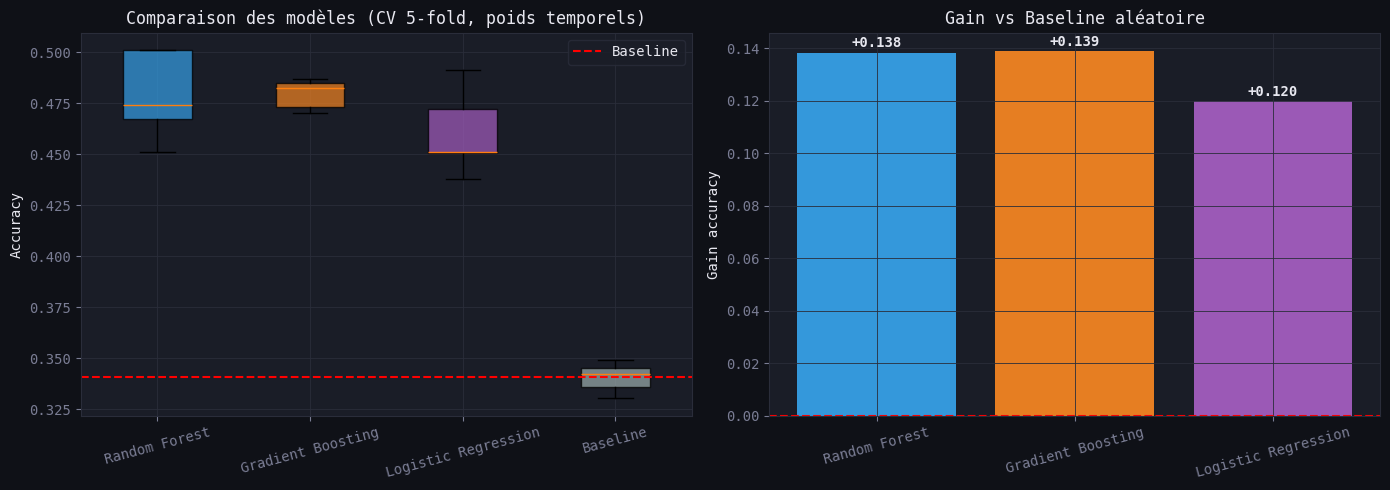

In [130]:
# @title
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

all_scores = {**results_cv, 'Baseline': baseline_scores}
bp = axes[0].boxplot(all_scores.values(), labels=all_scores.keys(), patch_artist=True)
for patch, color in zip(bp['boxes'], ['#3498db','#e67e22','#9b59b6','#95a5a6']):
    patch.set_facecolor(color); patch.set_alpha(0.75)
axes[0].axhline(baseline_scores.mean(), color='red', linestyle='--', label='Baseline')
axes[0].set_title('Comparaison des modèles (CV 5-fold, poids temporels)')
axes[0].set_ylabel('Accuracy'); axes[0].tick_params(axis='x', rotation=15)
axes[0].legend()

gains = {n: s.mean() - baseline_scores.mean() for n, s in results_cv.items()}
bars  = axes[1].bar(gains.keys(), gains.values(), color=['#3498db','#e67e22','#9b59b6'])
axes[1].axhline(0, color='red', linestyle='--')
for bar, val in zip(bars, gains.values()):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                 f'+{val:.3f}', ha='center', fontsize=10, fontweight='bold')
axes[1].set_title('Gain vs Baseline aléatoire')
axes[1].set_ylabel('Gain accuracy'); axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

Les résultats de la validation croisée confirment la forte valeur prédictive de notre feature engineering : tous les algorithmes surpassent très nettement la baseline aléatoire (34.1%). Le Random Forest et le gradient boosting s'imposent comme les modèles les plus performants avec environ 48% de précision moyenne (+ environ 14 points de gain)

## 4.4 - Importance des features

In [138]:
best_name  = max(results_cv, key=lambda k: results_cv[k].mean())
best_model = models[best_name]
best_model.fit(X, y, **{'clf__sample_weight': sample_weights})

print(f'Meilleur modèle : {best_name}  (acc CV = {results_cv[best_name].mean():.3f})')
print('Entraînement terminé (avec pondération temporelle)')

Meilleur modèle : Gradient Boosting  (acc CV = 0.480)
Entraînement terminé (avec pondération temporelle)


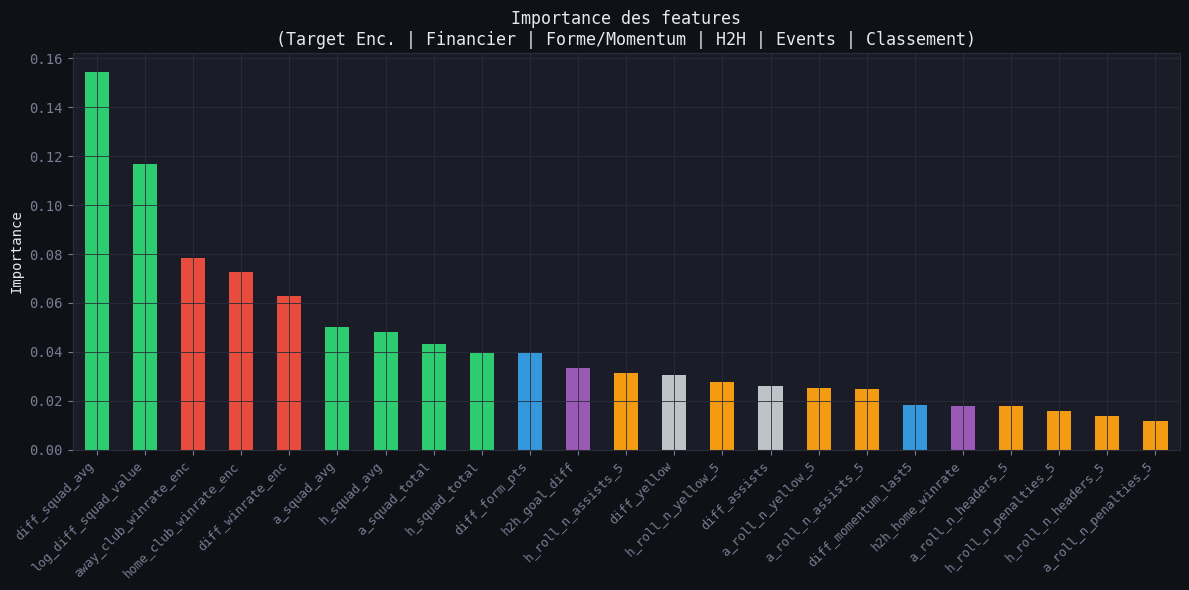

In [139]:
if hasattr(best_model.named_steps['clf'], 'feature_importances_'):
    fi = pd.Series(best_model.named_steps['clf'].feature_importances_,
                   index=FEATURE_COLS).sort_values(ascending=False)

    color_map = {
        'enc':      '#e74c3c',
        'squad':    '#2ecc71',
        'log_diff': '#2ecc71',
        'momentum': '#3498db',
        'form':     '#3498db',
        'h2h':      '#9b59b6',
        'position': '#95a5a6',
        'roll':     '#f39c12',
    }
    def get_color(feat):
        for key, color in color_map.items():
            if key in feat:
                return color
        return '#bdc3c7'

    fig, ax = plt.subplots(figsize=(12, 6))
    fi.plot(kind='bar', ax=ax, color=[get_color(c) for c in fi.index])
    ax.set_title('Importance des features\n'
                 '(Target Enc. | Financier | Forme/Momentum | H2H | Events | Classement)')
    ax.set_ylabel('Importance')
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.tight_layout()
    plt.show()

### Analyse de l'importance des features

Ce graphique confirme de manière frappante la réalité du football moderne et valide nos hypothèses de départ : la puissance structurelle prime sur la dynamique à court terme. Les indicateurs financiers dominent largement l'arbre de décision, confirmant que la valeur marchande d'un effectif reste le prédicteur numéro un du rapport de force. Vient ensuite le statut naturel du club qui assoit la hiérarchie globale. Enfin, les variables de forme récente et les profils de jeu occupent un rôle secondaire mais essentiel : elles agissent comme des variables d'ajustement.

---
## **5. Prédictions 2025-2026**

Cette étape construit la matrice de prédiction de la saison 2025-2026 en extrayant les toutes dernières statistiques connues de chaque équipe (forme récente, valeur financière, historique) afin de recréer le contexte initial des futures rencontres pour notre modèle final.

In [134]:
def build_features_2025(matches_2025, df_hist, squad_value_by_year,
                         momentum_all, events_per_match,
                         last_home_enc, last_away_enc, hist_avg_pos):
    feat = matches_2025[['game_id','date','home_club_id','away_club_id']].copy()

    last_home_form = (df_hist.sort_values('date')
                     .groupby('home_club_id')[['home_form_pts']].last().reset_index())
    last_away_form = (df_hist.sort_values('date')
                     .groupby('away_club_id')[['away_form_pts']].last().reset_index())
    feat = feat.merge(last_home_form, on='home_club_id', how='left')
    feat = feat.merge(last_away_form, on='away_club_id', how='left')
    feat['diff_form_pts'] = feat['home_form_pts'] - feat['away_form_pts']

    last_mom = (momentum_all.sort_values('date')
                .groupby('team_id')[['momentum_last5']].last().reset_index())
    feat = feat.merge(
        last_mom.rename(columns={'team_id':'home_club_id','momentum_last5':'h_momentum_last5'}),
        on='home_club_id', how='left'
    ).merge(
        last_mom.rename(columns={'team_id':'away_club_id','momentum_last5':'a_momentum_last5'}),
        on='away_club_id', how='left'
    )
    feat['diff_momentum_last5'] = feat['h_momentum_last5'] - feat['a_momentum_last5']

    hist_sorted = df_hist.sort_values('date').copy()
    hist_sorted['pair_key'] = hist_sorted.apply(
        lambda r: tuple(sorted([r['home_club_id'],r['away_club_id']])), axis=1)
    h2h_rows = []
    for _, row in matches_2025.iterrows():
        home_id, away_id = row['home_club_id'], row['away_club_id']
        pair = tuple(sorted([home_id, away_id]))
        past = hist_sorted[hist_sorted['pair_key'] == pair].tail(5)
        n = len(past)
        if n == 0:
            h2h_rows.append({'game_id':row['game_id'],'h2h_goal_diff':np.nan,
                              'h2h_home_winrate':np.nan,'h2h_n_games':0})
            continue
        hg = np.where(past['home_club_id']==home_id, past['home_club_goals'], past['away_club_goals'])
        ag = np.where(past['home_club_id']==away_id, past['home_club_goals'], past['away_club_goals'])
        hw = (((past['home_club_id']==home_id)&(past['results']==1)).sum() +
              ((past['away_club_id']==home_id)&(past['results']==-1)).sum())
        h2h_rows.append({'game_id':row['game_id'],'h2h_goal_diff':float((hg-ag).mean()),
                          'h2h_home_winrate':hw/n,'h2h_n_games':n})
    feat = feat.merge(pd.DataFrame(h2h_rows), on='game_id', how='left')

    feat = merge_squad_value(feat, squad_value_by_year)

    feat = feat.merge(last_home_enc, on='home_club_id', how='left')
    feat = feat.merge(last_away_enc, on='away_club_id', how='left')
    feat['diff_winrate_enc'] = feat['home_club_winrate_enc'] - feat['away_club_winrate_enc']

    last_ev = (events_per_match.sort_values('date')
               .groupby('club_id')[[f'roll_{c}_5' for c in
                                    ['n_assists','n_headers','n_penalties','n_regular','n_yellow','n_red']]]
               .last().reset_index())
    actual_roll_cols = [c for c in last_ev.columns if c != 'club_id']
    feat = feat.merge(
        last_ev.rename(columns={'club_id':'home_club_id'} | {c:f'h_{c}' for c in actual_roll_cols}),
        on='home_club_id', how='left'
    ).merge(
        last_ev.rename(columns={'club_id':'away_club_id'} | {c:f'a_{c}' for c in actual_roll_cols}),
        on='away_club_id', how='left'
    )
    feat['diff_assists'] = feat['h_roll_n_assists_5'] - feat['a_roll_n_assists_5']
    feat['diff_yellow']  = feat['h_roll_n_yellow_5']  - feat['a_roll_n_yellow_5']
    feat = merge_historical_position(feat, hist_avg_pos)

    return feat

print('Construction des features 2025')
features_2025 = build_features_2025(
    matches_2025, df_work, squad_value_by_year,
    momentum_all, events_per_match,
    last_home_enc, last_away_enc, hist_avg_pos)

X_2025 = features_2025[FEATURE_COLS].values
print(f'Matrice de prédiction : {X_2025.shape}')

Construction des features 2025
Matrice de prédiction : (233, 23)


Prédictions : 233 matchs
Distribution : {-1: 76, 0: 65, 1: 92}


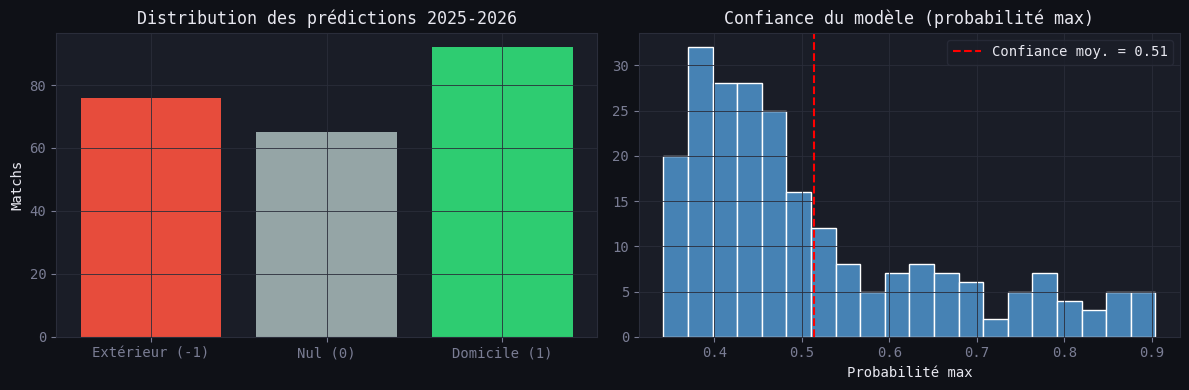

In [135]:
predictions = best_model.predict(X_2025)
probas      = best_model.predict_proba(X_2025)

unique, counts = np.unique(predictions, return_counts=True)
print(f'Prédictions : {len(predictions)} matchs')
print('Distribution :', {int(k): int(v) for k, v in zip(unique, counts)})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(['Extérieur (-1)','Nul (0)','Domicile (1)'],
            [int(counts[list(unique).index(k)]) if k in unique else 0 for k in [-1,0,1]],
            color=['#e74c3c','#95a5a6','#2ecc71'])
axes[0].set_title('Distribution des prédictions 2025-2026')
axes[0].set_ylabel('Matchs')

axes[1].hist(probas.max(axis=1), bins=20, color='steelblue', edgecolor='white')
axes[1].axvline(probas.max(axis=1).mean(), color='red', linestyle='--',
                label=f'Confiance moy. = {probas.max(axis=1).mean():.2f}')
axes[1].set_title('Confiance du modèle (probabilité max)')
axes[1].set_xlabel('Probabilité max'); axes[1].legend()
plt.tight_layout()
plt.show()

##Analyse et Interprétation finale des prédictions

Le graphique de gauche illustre la répartition des prédictions générées par notre modèle. On constate que le modèle ne tombe pas dans le piège d'une prédiction paresseuse qui consisterait à annoncer systématiquement l'équipe receveuse gagnante. La hiérarchie des barres (majorité de victoires à domicile, suivies des victoires à l'extérieur, puis des matchs nuls) reflète fidèlement la distribution historique naturelle de la Ligue 1 (historiquement autour de 44% - 30% - 26%). Cela valide l'efficacité de notre paramétrage (class_weight='balanced') et prouve que le modèle s'appuie sur nos variables de contexte pour prendre des décisions véritablement nuancées.

-------

L'histogramme de droite mesure la confiance du modèle en les prédictions. Avec une confiance moyenne mesurée 51%, l'algorithme affiche un comportement réaliste pour de la prédiction sportive.

La majorité des prédictions se concentrent entre 0.35 et 0.50. Sachant que le hasard pur sur 3 issues représente 33%, le modèle exprime ici une légère préférence argumentée, reconnaissant l'incertitude inhérente à des matchs opposant des équipes de niveau similaire.

Cependant la longue traîne qui s'étire vers la droite (jusqu'à 0.9 de probabilité) représente les rencontres où le modèle est très sûr de lui. Ces pics de confiance correspondent logiquement aux matchs présentant des rapports de force extrêmes (fort différentiel financier, meilleurs équipes de Ligue 1 face à des équipes de bas tableau)

---
## 6. Export

In [136]:
# @title
submission = pd.DataFrame({
    'game_id': matches_2025['game_id'],
    'results': predictions
})

assert submission['results'].isin([-1, 0, 1]).all(), 'Résultats invalides'
assert set(submission.columns) == set(sample_results.columns), 'Colonnes incorrectes'

submission.to_csv('predictions_2025_2026_v4.csv', index=False)
print('Fichier sauvegardé : predictions_2025_2026_v4.csv')

final_view = (
    matches_2025[['game_id','date','home_club_name','away_club_name']]
    .merge(submission, on='game_id')
    .merge(features_2025[['game_id','home_club_winrate_enc','away_club_winrate_enc',
                            'h_momentum_last5','h2h_goal_diff']],
           on='game_id', how='left')
)
final_view['prédiction'] = final_view['results'].map(
    {1:'Domicile', 0:'Nul', -1:'Extérieur'}
)
print()
print(final_view[['date','home_club_name','away_club_name',
                   'home_club_winrate_enc','away_club_winrate_enc',
                   'h_momentum_last5','prédiction']]
      .head(12).round(2).to_string(index=False))

Fichier sauvegardé : predictions_2025_2026_v4.csv

      date                               home_club_name                               away_club_name  home_club_winrate_enc  away_club_winrate_enc  h_momentum_last5 prédiction
2025-08-15                  Stade Rennais Football Club                       Olympique de Marseille                   0.48                   0.43               0.6  Extérieur
2025-08-16                          Racing Club de Lens                           Olympique Lyonnais                   0.49                   0.45               0.4  Extérieur
2025-08-16     Olympique Gymnaste Club Nice Côte d'Azur                       Toulouse Football Club                   0.52                   0.24               0.6   Domicile
2025-08-17        Association de la Jeunesse auxerroise           Football Club Lorient-Bretagne Sud                   0.34                   0.20               0.2  Extérieur
2025-08-17                            Stade brestois 29              